## Imports

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU: Tesla T4


## Load Dataset

In [3]:
from pathlib import Path

for file in Path("/content/Data").rglob("cardio_train.csv"):
    print(file)

/content/Data/cardio_train.csv


In [4]:
DATA_PATH = "/content/Data/cardio_train.csv"

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


##Verifiy Dataset

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows: 70000
Number of columns: 13

Column names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Data types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 no

In [6]:
expected_columns = [
    "id", "age", "gender", "height", "weight",
    "ap_hi", "ap_lo", "cholesterol", "gluc",
    "smoke", "alco", "active", "cardio"
]

assert df.shape[1] == 13, "Unexpected number of columns!"
assert df.columns.tolist() == expected_columns, "Unexpected column structure!"
assert df.shape[0] == 70000, "Unexpected number of records!"
assert df["cardio"].isin([0, 1]).all(), "Invalid target values!"

print("All initial dataset checks passed!")

All initial dataset checks passed!


## EDA

In [7]:
# Basic dataset information
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)

Dataset Shape: (70000, 13)

Data Types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [8]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

,Missing Count,Missing Percentage
id,0,0.0
age,0,0.0
gender,0,0.0
height,0,0.0
weight,0,0.0
ap_hi,0,0.0
ap_lo,0,0.0
cholesterol,0,0.0
gluc,0,0.0
smoke,0,0.0


In [9]:
# Exact duplicate rows
exact_duplicates = df.duplicated().sum()

# Duplicate patient features, excluding ID
feature_columns = [col for col in df.columns if col != "id"]

duplicate_features = df.duplicated(
    subset=feature_columns,
    keep=False
).sum()

# Check identical features with conflicting cardio labels
label_conflicts = (
    df.groupby(feature_columns)["cardio"]
    .nunique()
)

conflicting_groups = (label_conflicts > 1).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Rows involved in duplicate feature combinations:", duplicate_features)
print("Conflicting target groups:", conflicting_groups)

Exact duplicate rows: 0
Rows involved in duplicate feature combinations: 48
Conflicting target groups: 0


Class Counts:
cardio
0    35021
1    34979
Name: count, dtype: int64

Class Percentages:
cardio
0    50.03
1    49.97
Name: proportion, dtype: float64


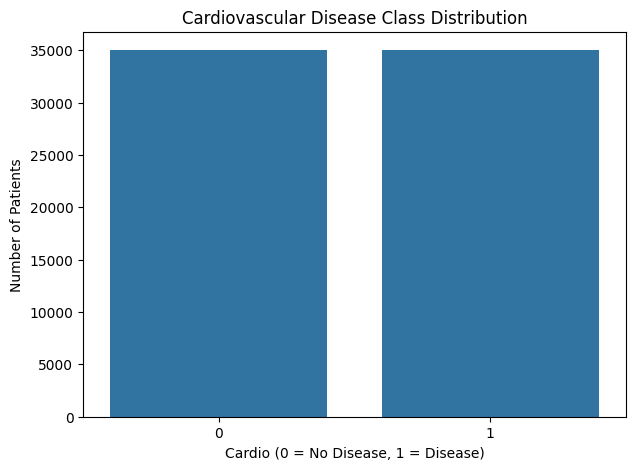

In [10]:
target_counts = df["cardio"].value_counts().sort_index()

target_percentages = df["cardio"].value_counts(
    normalize=True
).sort_index() * 100

print("Class Counts:")
print(target_counts)

print("\nClass Percentages:")
print(target_percentages)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="cardio")

plt.title("Cardiovascular Disease Class Distribution")
plt.xlabel("Cardio (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.show()

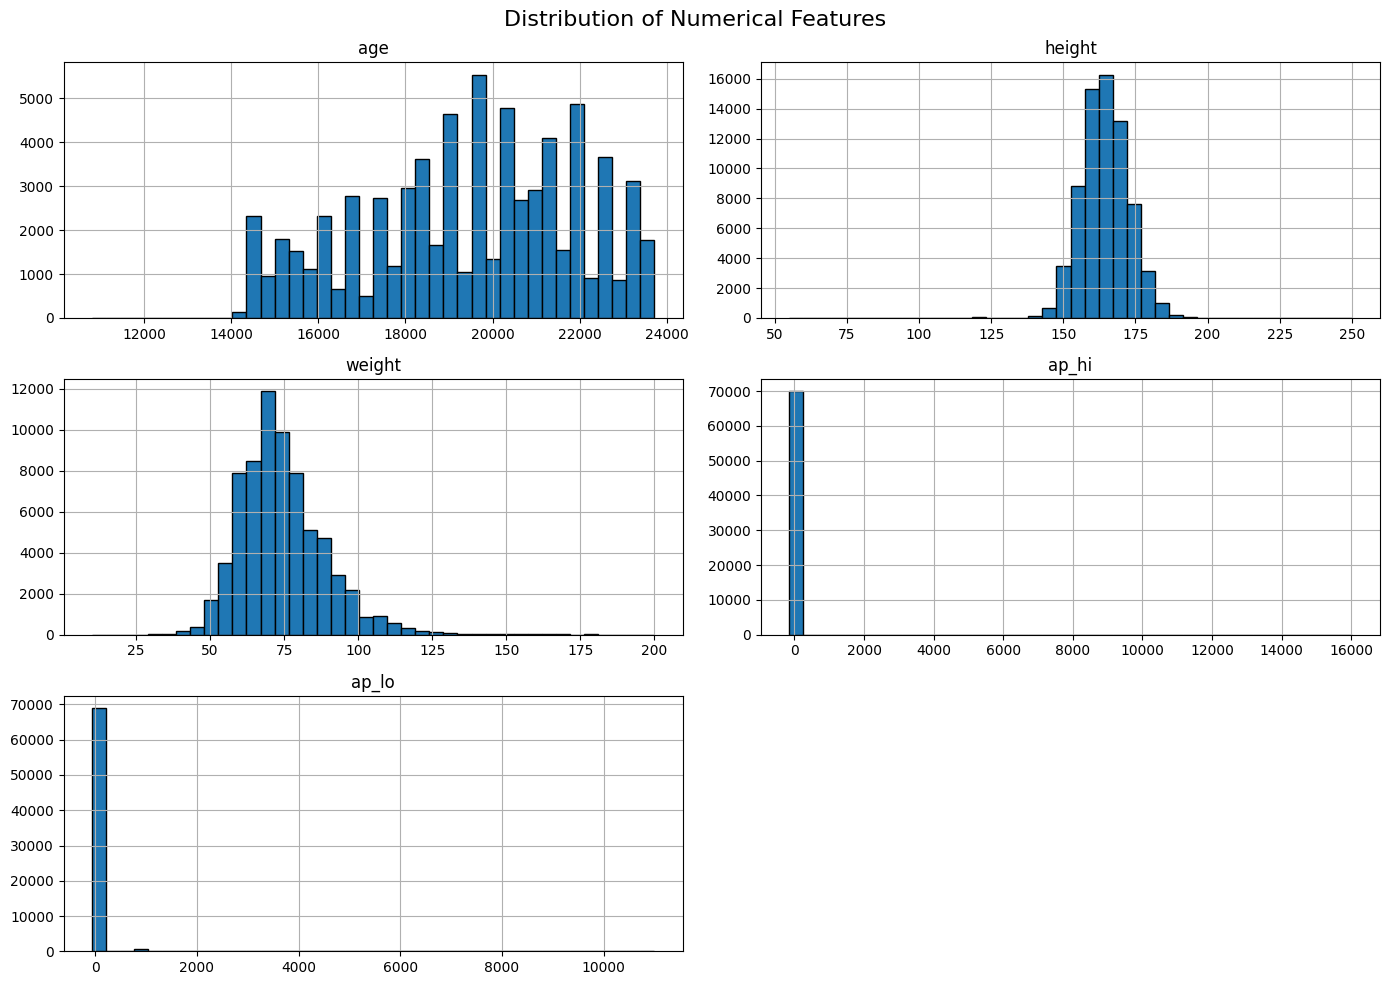

In [11]:
numerical_features = [
    "age", "height", "weight", "ap_hi", "ap_lo"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=40,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

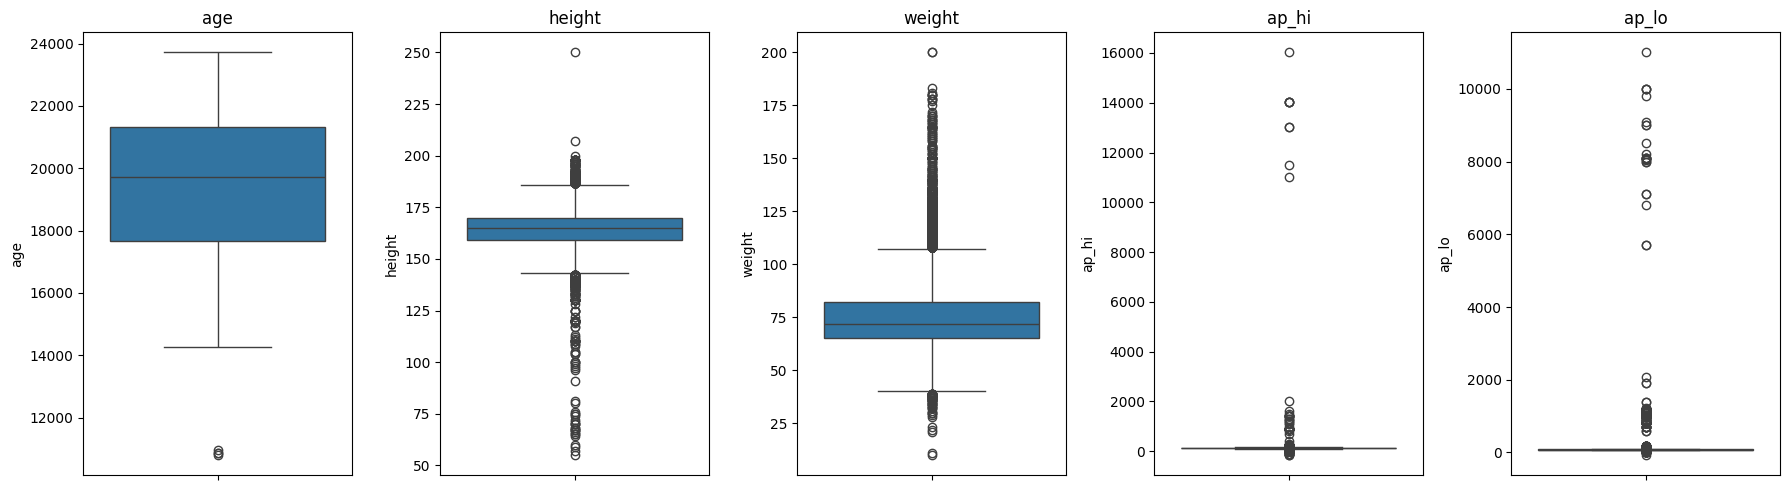

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for i, feature in enumerate(numerical_features):
    sns.boxplot(y=df[feature], ax=axes[i])
    axes[i].set_title(feature)

plt.tight_layout()
plt.show()

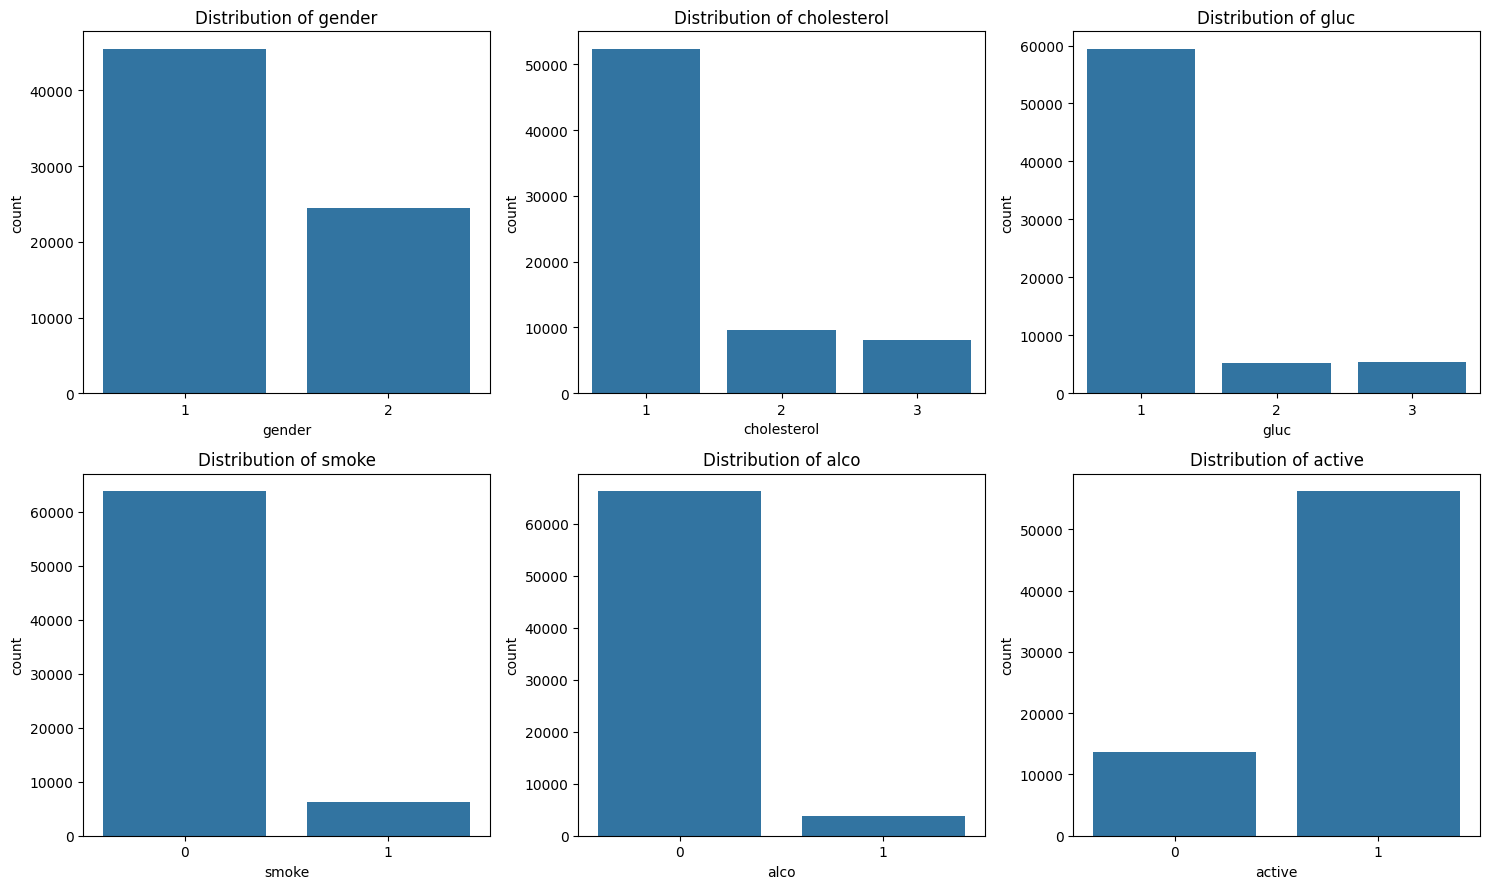

In [13]:
categorical_features = [
    "gender",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(categorical_features, axes.flatten()):
    sns.countplot(data=df, x=feature, ax=ax)
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

In [14]:
for feature in categorical_features + ["cardio"]:
    print(f"\n{feature}:")
    print(sorted(df[feature].dropna().unique()))


gender:
[np.int64(1), np.int64(2)]

cholesterol:
[np.int64(1), np.int64(2), np.int64(3)]

gluc:
[np.int64(1), np.int64(2), np.int64(3)]

smoke:
[np.int64(0), np.int64(1)]

alco:
[np.int64(0), np.int64(1)]

active:
[np.int64(0), np.int64(1)]

cardio:
[np.int64(0), np.int64(1)]


In [15]:
print("Systolic BP (ap_hi):")
print(df["ap_hi"].describe())

print("\nDiastolic BP (ap_lo):")
print(df["ap_lo"].describe())

# Basic logical checks
print("\nInvalid or suspicious measurements:")

print("Systolic <= 0:", (df["ap_hi"] <= 0).sum())
print("Diastolic <= 0:", (df["ap_lo"] <= 0).sum())

print("Systolic < Diastolic:",
      (df["ap_hi"] < df["ap_lo"]).sum())

print("Systolic == Diastolic:",
      (df["ap_hi"] == df["ap_lo"]).sum())

Systolic BP (ap_hi):
count    70000.000000
mean       128.817286
std        154.011419
min       -150.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64

Diastolic BP (ap_lo):
count    70000.000000
mean        96.630414
std        188.472530
min        -70.000000
25%         80.000000
50%         80.000000
75%         90.000000
max      11000.000000
Name: ap_lo, dtype: float64

Invalid or suspicious measurements:
Systolic <= 0: 7
Diastolic <= 0: 22
Systolic < Diastolic: 1234
Systolic == Diastolic: 2


In [16]:
print("Lowest systolic readings:")
display(df.nsmallest(15, "ap_hi")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

print("Highest systolic readings:")
display(df.nlargest(15, "ap_hi")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

print("Lowest diastolic readings:")
display(df.nsmallest(15, "ap_lo")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

print("Highest diastolic readings:")
display(df.nlargest(15, "ap_lo")[
    ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cardio"]
])

Lowest systolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
35040,23325,2,168,59.0,-150,80,1
23988,18301,1,162,74.0,-140,90,1
25240,14711,2,168,50.0,-120,80,1
46627,23646,2,160,59.0,-120,80,0
16021,22108,2,161,90.0,-115,70,0
4607,15281,1,165,78.0,-100,80,0
20536,15581,1,153,54.0,-100,70,0
8757,16905,2,163,63.0,1,2088,0
42334,18716,1,171,80.0,1,1088,1
5382,21240,1,162,69.0,7,80,0


Highest systolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
40852,17438,1,169,70.0,16020,80,1
25464,15835,2,169,75.0,14020,80,1
25519,21361,1,169,71.0,14020,80,1
46912,16910,2,180,78.0,14020,90,1
47253,19731,1,160,65.0,14020,90,0
55459,18307,1,152,76.0,13010,80,1
55847,23182,1,161,105.0,13010,80,0
7763,21032,1,175,80.0,11500,90,1
51438,18784,2,168,65.0,11020,80,1
69370,14696,1,170,74.0,2000,100,1


Lowest diastolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
60106,22571,1,167,74.0,15,-70,1
2014,22712,2,167,59.0,906,0,0
13489,14965,2,150,60.0,130,0,0
16459,20457,1,156,50.0,138,0,1
17381,18226,1,164,78.0,138,0,0
22923,21182,2,166,68.0,149,0,1
23867,16131,1,161,92.0,906,0,1
25454,17952,2,176,73.0,12,0,0
27686,23396,2,180,73.0,140,0,1
31783,16070,1,170,64.0,907,0,0


Highest diastolic readings:


,age,gender,height,weight,ap_hi,ap_lo,cardio
43326,23221,1,160,105.0,200,11000,1
2381,20994,2,186,105.0,140,10000,1
23849,18102,2,169,86.0,150,10000,1
68538,19062,1,166,70.0,160,10000,1
43434,21906,2,179,62.0,130,9800,0
6653,19528,1,162,69.0,130,9100,1
12086,21466,2,169,78.0,130,9011,1
32920,18335,1,156,65.0,150,9011,1
15990,14508,2,179,70.0,120,8500,0
44042,21220,1,165,74.0,120,8200,0


In [17]:
print("Lowest heights:")
display(df.nsmallest(15, "height"))

print("\nHighest heights:")
display(df.nlargest(15, "height"))

print("\nLowest weights:")
display(df.nsmallest(15, "weight"))

print("\nHighest weights:")
display(df.nlargest(15, "weight"))

Lowest heights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
22723,32456,23386,1,55,81.0,130,90,1,1,0,0,1,1
66643,95141,18830,1,57,61.0,130,90,1,1,0,0,1,1
64115,91523,18426,1,59,57.6,125,67,1,1,0,0,0,0
29157,41661,19088,1,60,69.0,110,70,1,1,0,0,0,0
27603,39462,20978,1,64,61.0,130,70,1,1,0,0,1,0
33607,48009,19709,2,65,72.0,130,80,1,1,0,0,0,0
44490,63545,19120,1,65,60.0,120,80,1,1,0,0,1,0
64454,92008,21348,1,66,63.0,12,80,1,1,0,0,0,1
14323,20459,22005,1,67,57.0,120,90,1,1,0,0,1,1
50789,72476,14499,2,67,60.0,110,80,1,1,1,1,1,0



Highest heights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
6486,9223,21220,1,250,86.0,140,100,3,1,0,0,1,1
21628,30894,19054,2,207,78.0,100,70,1,1,0,1,1,0
41901,59847,19187,2,200,100.0,170,1100,2,2,0,0,1,1
1117,1554,22156,2,198,68.0,120,80,1,1,0,0,1,1
3237,4561,16072,2,198,61.0,110,70,1,1,0,0,1,1
8897,12687,22497,2,198,79.0,160,100,1,1,1,0,0,1
12007,17138,18258,2,198,102.0,110,70,1,1,0,0,1,0
29145,41642,21812,2,198,90.0,130,90,1,1,0,0,1,1
30127,43083,23274,1,198,85.0,110,90,1,1,0,0,1,0
30238,43248,20381,1,198,89.0,120,80,1,1,0,0,1,0



Lowest weights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
57858,82567,18804,2,165,10.0,180,1100,2,2,0,0,1,1
33817,48318,21582,2,178,11.0,130,90,1,1,0,0,1,1
60188,85931,21855,1,162,21.0,120,80,2,1,0,0,1,1
29488,42156,20408,2,177,22.0,120,80,1,1,1,1,1,0
26806,38312,23284,1,157,23.0,110,80,1,1,0,0,1,0
34276,48976,14664,2,128,28.0,120,80,1,1,0,0,1,0
60699,86650,18875,1,171,29.0,110,70,2,1,0,0,1,1
3752,5306,15400,1,120,30.0,110,70,1,1,0,0,1,0
18559,26503,18140,1,160,30.0,120,80,1,1,0,0,1,1
41905,59853,21334,1,143,30.0,103,61,2,1,0,0,1,0



Highest weights:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
435,618,16765,1,186,200.0,130,70,1,1,0,0,0,0
50413,71945,15117,2,180,200.0,150,90,1,1,0,0,1,1
61285,87498,20939,2,180,183.0,110,80,3,3,0,1,1,1
36780,52564,19630,1,161,181.0,180,1100,2,1,0,0,1,1
4743,6716,17218,2,176,180.0,140,90,1,1,0,0,1,1
45378,64829,17418,2,190,180.0,140,80,2,2,0,0,1,1
60592,86506,18975,2,180,180.0,140,100,3,1,0,0,1,1
61362,87612,16615,2,196,180.0,130,80,3,1,0,0,1,1
20092,28683,20656,2,165,178.0,120,80,1,1,1,1,1,0
27384,39156,15292,1,80,178.0,140,90,3,3,0,0,1,1


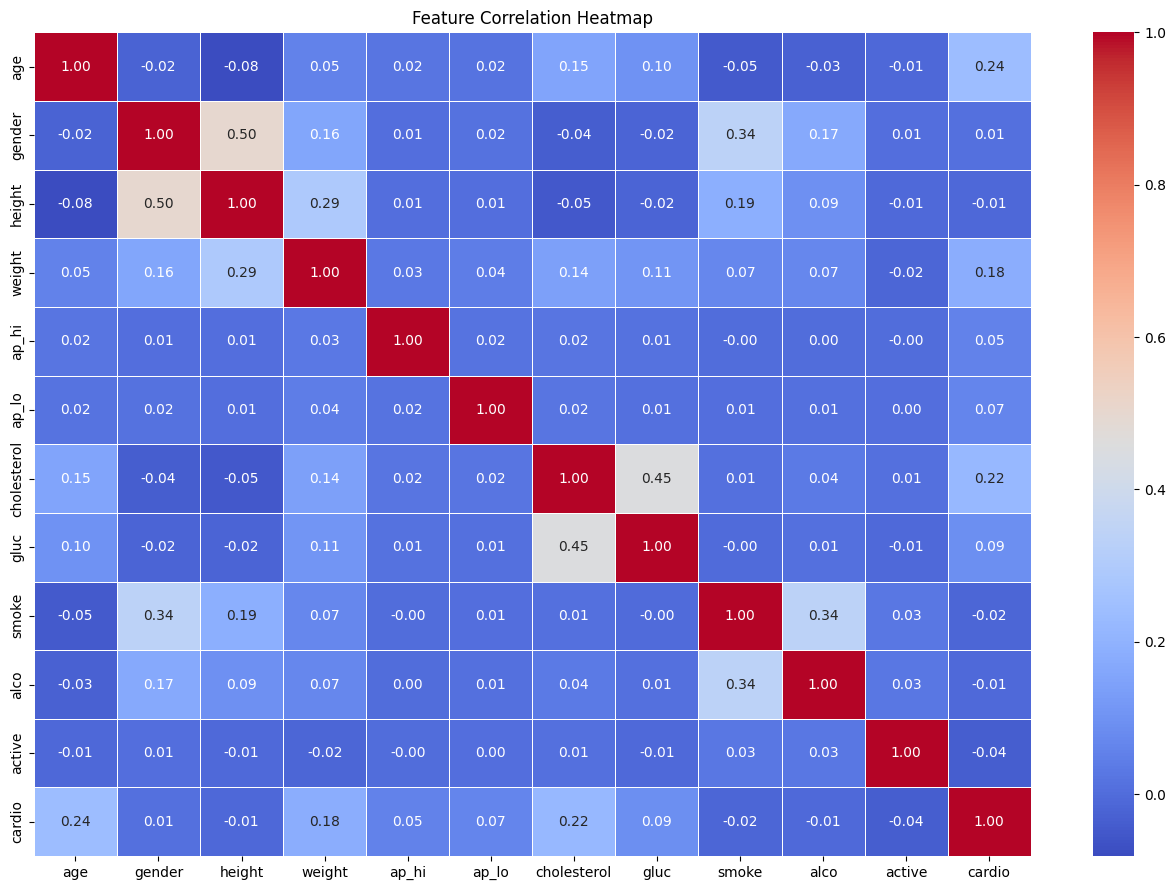

In [18]:
plt.figure(figsize=(13, 9))

correlation = df.drop(columns=["id"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

##Preprocess Part 1

In [19]:
df["age_years"] = df["age"] / 365.25

print(df["age_years"].describe())

count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age_years, dtype: float64


In [20]:
# Define candidate conditions
flags = pd.DataFrame(index=df.index)

flags["height_invalid"] = (
    (df["height"] < 120) |
    (df["height"] > 220)
)

flags["weight_invalid"] = (
    (df["weight"] < 30) |
    (df["weight"] > 200)
)

flags["systolic_invalid"] = (
    (df["ap_hi"] < 70) |
    (df["ap_hi"] > 250)
)

flags["diastolic_invalid"] = (
    (df["ap_lo"] < 40) |
    (df["ap_lo"] > 150)
)

flags["bp_relationship_invalid"] = (
    df["ap_hi"] <= df["ap_lo"]
)

# Summary
print("Suspicious measurements by feature:\n")

print(flags.sum())

print("\nRecords with at least one suspicious measurement:")

print(flags.any(axis=1).sum())

print("\nRecords with multiple suspicious measurements:")

print((flags.sum(axis=1) > 1).sum())

Suspicious measurements by feature:

height_invalid               53
weight_invalid                7
systolic_invalid            229
diastolic_invalid          1034
bp_relationship_invalid    1236
dtype: int64

Records with at least one suspicious measurement:
1390

Records with multiple suspicious measurements:
1161


In [21]:
suspicious_records = df.loc[
    flags.any(axis=1),
    [
        "id", "age_years", "gender",
        "height", "weight",
        "ap_hi", "ap_lo",
        "cholesterol", "gluc", "cardio"
    ]
].copy()

display(suspicious_records.head(30))

print("Total suspicious records:", len(suspicious_records))

,id,age_years,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,cardio
224,309,59.685147,2,76,55.0,120,80,1,1,0
228,314,47.882272,2,183,98.0,160,1100,1,2,1
241,334,60.046543,2,157,60.0,160,1000,2,1,1
260,357,49.875428,1,150,83.0,140,800,1,1,1
329,458,64.084873,1,176,63.0,160,1000,2,2,1
345,482,51.208761,1,154,81.0,140,1000,2,1,1
418,594,45.607118,1,157,72.0,150,30,1,1,1
473,680,41.686516,1,150,95.0,150,1033,1,1,1
474,681,52.290212,1,156,65.0,120,150,2,1,0
559,805,55.934292,2,173,101.0,200,1000,1,1,1


Total suspicious records: 1390


In [22]:
# Extremely high or low systolic readings
extreme_systolic = df[
    (df["ap_hi"] < 70) |
    (df["ap_hi"] > 250)
]

# Extremely high or low diastolic readings
extreme_diastolic = df[
    (df["ap_lo"] < 40) |
    (df["ap_lo"] > 150)
]

# Systolic lower than or equal to diastolic
invalid_relationship = df[
    df["ap_hi"] <= df["ap_lo"]
]

print("Extreme systolic readings:", len(extreme_systolic))
print("Extreme diastolic readings:", len(extreme_diastolic))
print("Invalid BP relationship:", len(invalid_relationship))

print("\nExamples of invalid BP relationships:")

display(
    invalid_relationship[
        ["id", "ap_hi", "ap_lo", "cardio"]
    ].head(20)
)

Extreme systolic readings: 229
Extreme diastolic readings: 1034
Invalid BP relationship: 1236

Examples of invalid BP relationships:


,id,ap_hi,ap_lo,cardio
228,314,160,1100,1
241,334,160,1000,1
260,357,140,800,1
329,458,160,1000,1
345,482,140,1000,1
473,680,150,1033,1
474,681,120,150,0
559,805,200,1000,1
567,815,14,90,1
613,886,140,1000,1


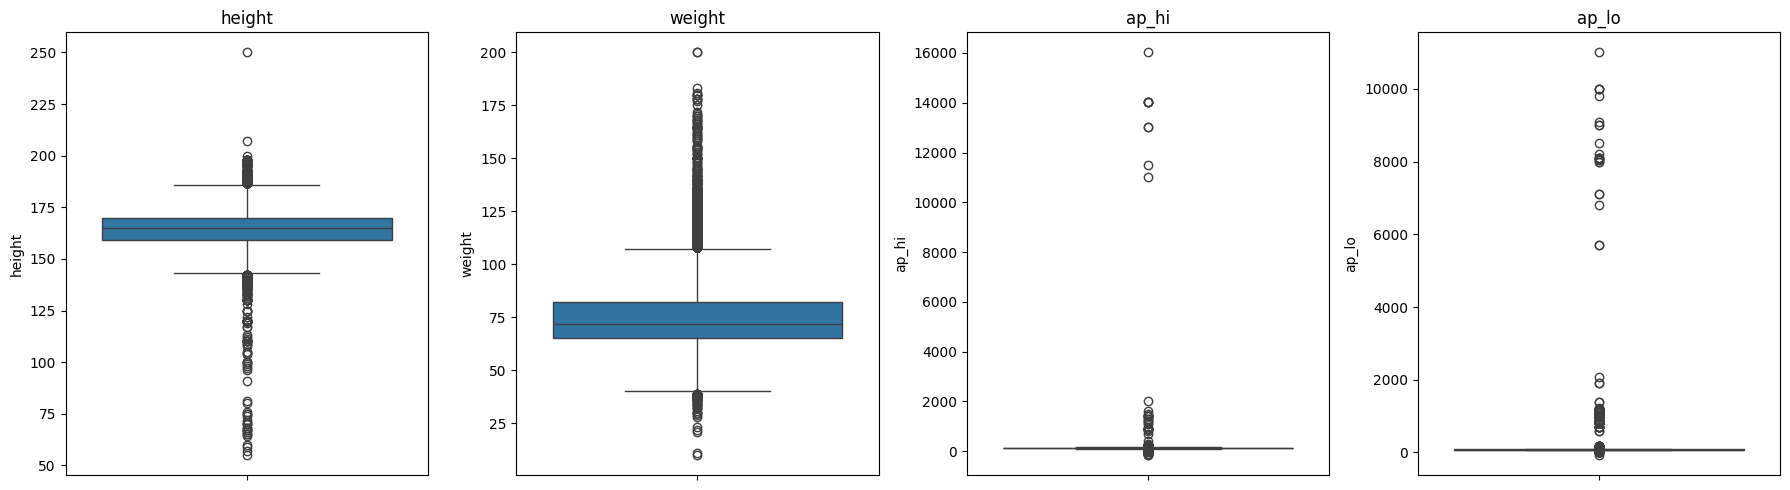

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

features = ["height", "weight", "ap_hi", "ap_lo"]

for feature, ax in zip(features, axes):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

##Preprocess Part 2 (Cleanning)

In [24]:
df_work = df.copy()

# Convert age from days to years
df_work["age"] = df_work["age"] / 365.25

print("Age converted successfully!")
print(df_work["age"].describe())

Age converted successfully!
count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age, dtype: float64


In [25]:
# Height validation
valid_height = df_work["height"].between(120, 220)

# Weight validation
valid_weight = df_work["weight"].between(30, 200)

# Systolic blood pressure validation
valid_systolic = df_work["ap_hi"].between(70, 250)

# Diastolic blood pressure validation
valid_diastolic = df_work["ap_lo"].between(40, 150)

# Blood pressure relationship
valid_bp_relationship = df_work["ap_hi"] > df_work["ap_lo"]

# Combine all conditions
valid_records = (
    valid_height &
    valid_weight &
    valid_systolic &
    valid_diastolic &
    valid_bp_relationship
)

print("Cleaning rule results:")
print("Invalid height:", (~valid_height).sum())
print("Invalid weight:", (~valid_weight).sum())
print("Invalid systolic BP:", (~valid_systolic).sum())
print("Invalid diastolic BP:", (~valid_diastolic).sum())
print("Invalid BP relationship:", (~valid_bp_relationship).sum())

print("\nTotal records flagged:", (~valid_records).sum())
print("Records retained:", valid_records.sum())

Cleaning rule results:
Invalid height: 53
Invalid weight: 7
Invalid systolic BP: 229
Invalid diastolic BP: 1034
Invalid BP relationship: 1236

Total records flagged: 1390
Records retained: 68610


In [26]:
# Keep only valid records
df_clean = df_work.loc[valid_records].copy()

# Remove patient ID
df_clean.drop(columns=["id"], inplace=True)

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemoved records:", len(df) - len(df_clean))
print("Retained records:", len(df_clean))

Original dataset shape: (70000, 14)
Cleaned dataset shape: (68610, 13)

Removed records: 1390
Retained records: 68610


In [27]:
print("Missing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate records:")
print(df_clean.duplicated().sum())

print("\nFeature ranges:")
display(df_clean.describe().T)

print("\nTarget distribution:")
print(df_clean["cardio"].value_counts())

print("\nTarget percentages:")
print(df_clean["cardio"].value_counts(normalize=True) * 100)

Missing values:
0

Duplicate records:
24

Feature ranges:


,count,mean,std,min,25%,50%,75%,max
age,68610.0,53.291488,6.757042,29.563313,48.344969,53.941136,58.38193,64.922656
gender,68610.0,1.348637,0.476542,1.000000,1.000000,1.000000,2.00000,2.000000
height,68610.0,164.413249,7.912820,120.000000,159.000000,165.000000,170.00000,207.000000
weight,68610.0,74.114763,14.296269,30.000000,65.000000,72.000000,82.00000,200.000000
ap_hi,68610.0,126.670821,16.678033,70.000000,120.000000,120.000000,140.00000,240.000000
ap_lo,68610.0,81.301866,9.420957,40.000000,80.000000,80.000000,90.00000,150.000000
cholesterol,68610.0,1.364728,0.678930,1.000000,1.000000,1.000000,2.00000,3.000000
gluc,68610.0,1.225783,0.571638,1.000000,1.000000,1.000000,1.00000,3.000000
smoke,68610.0,0.087976,0.283261,0.000000,0.000000,0.000000,0.00000,1.000000
alco,68610.0,0.053360,0.224751,0.000000,0.000000,0.000000,0.00000,1.000000



Target distribution:
cardio
0    34669
1    33941
Name: count, dtype: int64

Target percentages:
cardio
0    50.530535
1    49.469465
Name: proportion, dtype: float64


In [28]:
assert df_clean["height"].between(120, 220).all()
assert df_clean["weight"].between(30, 200).all()
assert df_clean["ap_hi"].between(70, 250).all()
assert df_clean["ap_lo"].between(40, 150).all()
assert (df_clean["ap_hi"] > df_clean["ap_lo"]).all()

assert df_clean["cardio"].isin([0, 1]).all()

print("All clinical validation checks passed!")

All clinical validation checks passed!


In [29]:
cleaning_summary = pd.DataFrame({
    "Stage": [
        "Original dataset",
        "After clinical cleaning"
    ],
    "Records": [
        len(df),
        len(df_clean)
    ]
})

cleaning_summary["Removed"] = [
    0,
    len(df) - len(df_clean)
]

cleaning_summary["Retention Percentage"] = (
    cleaning_summary["Records"] / len(df) * 100
)

display(cleaning_summary)

,Stage,Records,Removed,Retention Percentage
0,Original dataset,70000,0,100.000000
1,After clinical cleaning,68610,1390,98.014286


##Verifiy Dataset after cleanning

In [30]:
# Start from original data, excluding the previously added age_years
df_work = df.drop(columns=["age_years"], errors="ignore").copy()

# Convert age from days to years
df_work["age"] = df_work["age"] / 365.25

# Define validation rules
valid_records = (
    df_work["height"].between(120, 220) &
    df_work["weight"].between(30, 200) &
    df_work["ap_hi"].between(70, 250) &
    df_work["ap_lo"].between(40, 150) &
    (df_work["ap_hi"] > df_work["ap_lo"])
)

# Create cleaned dataset
df_clean = df_work.loc[valid_records].copy()

# Remove ID
df_clean.drop(columns=["id"], inplace=True)

# Reset index
df_clean.reset_index(drop=True, inplace=True)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nExact duplicate rows:", df_clean.duplicated().sum())

Original shape: (70000, 14)
Cleaned shape: (68610, 12)

Columns:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Exact duplicate rows: 24


In [31]:
assert df_clean.shape == (68610, 12)
assert "id" not in df_clean.columns
assert "age_years" not in df_clean.columns
assert df_clean.isnull().sum().sum() == 0

print("Dataset verification passed!")

display(df_clean.describe().T)

Dataset verification passed!


,count,mean,std,min,25%,50%,75%,max
age,68610.0,53.291488,6.757042,29.563313,48.344969,53.941136,58.38193,64.922656
gender,68610.0,1.348637,0.476542,1.000000,1.000000,1.000000,2.00000,2.000000
height,68610.0,164.413249,7.912820,120.000000,159.000000,165.000000,170.00000,207.000000
weight,68610.0,74.114763,14.296269,30.000000,65.000000,72.000000,82.00000,200.000000
ap_hi,68610.0,126.670821,16.678033,70.000000,120.000000,120.000000,140.00000,240.000000
ap_lo,68610.0,81.301866,9.420957,40.000000,80.000000,80.000000,90.00000,150.000000
cholesterol,68610.0,1.364728,0.678930,1.000000,1.000000,1.000000,2.00000,3.000000
gluc,68610.0,1.225783,0.571638,1.000000,1.000000,1.000000,1.00000,3.000000
smoke,68610.0,0.087976,0.283261,0.000000,0.000000,0.000000,0.00000,1.000000
alco,68610.0,0.053360,0.224751,0.000000,0.000000,0.000000,0.00000,1.000000


##Data Splitting

In [32]:
from sklearn.model_selection import StratifiedGroupKFold

# Separate predictors and target
X = df_clean.drop(columns=["cardio"])
y = df_clean["cardio"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

Features shape: (68610, 11)
Target shape: (68610,)

Input features:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Target distribution:
cardio
0    50.530535
1    49.469465
Name: proportion, dtype: float64


In [33]:
# Each unique feature combination receives a group ID
groups = pd.factorize(
    X.apply(tuple, axis=1)
)[0]

print("Total records:", len(X))
print("Unique feature groups:", len(np.unique(groups)))
print("Duplicate records:", len(X) - len(np.unique(groups)))

Total records: 68610
Unique feature groups: 68569
Duplicate records: 41


In [34]:
sgkf_1 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, temp_idx = next(
    sgkf_1.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_temp = X.iloc[temp_idx].copy()

y_train = y.iloc[train_idx].copy()
y_temp = y.iloc[temp_idx].copy()

groups_train = groups[train_idx]
groups_temp = groups[temp_idx]

print("Training set:", X_train.shape)
print("Temporary set:", X_temp.shape)

Training set: (54889, 11)
Temporary set: (13721, 11)


In [35]:
sgkf_2 = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    sgkf_2.split(X_temp, y_temp, groups_temp)
)

X_val = X_temp.iloc[val_idx].copy()
X_test = X_temp.iloc[test_idx].copy()

y_val = y_temp.iloc[val_idx].copy()
y_test = y_temp.iloc[test_idx].copy()

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (54889, 11)
Validation set: (6862, 11)
Test set: (6859, 11)


In [36]:
total = len(df_clean)

splits = {
    "Training": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

for name, (features, target) in splits.items():
    print(f"\n{name} Set")
    print("-" * 35)
    print("Records:", len(features))
    print("Percentage:", round(len(features) / total * 100, 2), "%")
    print("Class distribution:")
    print(target.value_counts(normalize=True).sort_index() * 100)


Training Set
-----------------------------------
Records: 54889
Percentage: 80.0 %
Class distribution:
cardio
0    50.394432
1    49.605568
Name: proportion, dtype: float64

Validation Set
-----------------------------------
Records: 6862
Percentage: 10.0 %
Class distribution:
cardio
0    51.267852
1    48.732148
Name: proportion, dtype: float64

Test Set
-----------------------------------
Records: 6859
Percentage: 10.0 %
Class distribution:
cardio
0    50.882053
1    49.117947
Name: proportion, dtype: float64


In [37]:
train_groups = set(groups_train)

val_groups = set(groups_temp[val_idx])
test_groups = set(groups_temp[test_idx])

print("Train-Val overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Val-Test overlap:", len(val_groups & test_groups))

assert len(train_groups & val_groups) == 0
assert len(train_groups & test_groups) == 0
assert len(val_groups & test_groups) == 0

print("\nNo group leakage detected!")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

No group leakage detected!


In [38]:
assert len(X_train) + len(X_val) + len(X_test) == len(df_clean)

assert len(y_train) == len(X_train)
assert len(y_val) == len(X_val)
assert len(y_test) == len(X_test)

print("All splitting checks passed!")

All splitting checks passed!


In [39]:
from sklearn.preprocessing import StandardScaler

continuous_features = [
    "age",
    "height",
    "weight",
    "ap_hi",
    "ap_lo"
]

scaler = StandardScaler()

# Cast to float first so standardised values are not forced into integer columns
# (avoids a pandas FutureWarning / error on newer versions; results are unchanged)
for _df in (X_train, X_val, X_test):
    _df[continuous_features] = _df[continuous_features].astype(float)

# Fit ONLY on training data
X_train.loc[:, continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

# Transform validation and test using training statistics
X_val.loc[:, continuous_features] = scaler.transform(
    X_val[continuous_features]
)

X_test.loc[:, continuous_features] = scaler.transform(
    X_test[continuous_features]
)

print("Standardization completed!")

Standardization completed!


In [40]:
print("Training means:")
display(X_train[continuous_features].mean())

print("\nTraining standard deviations:")
display(X_train[continuous_features].std(ddof=0))

print("\nValidation means:")
display(X_val[continuous_features].mean())

print("\nTest means:")
display(X_test[continuous_features].mean())

Training means:


,0
age,-3.650514e-16
height,-7.207823e-16
weight,-3.482228e-17
ap_hi,3.971552e-16
ap_lo,3.026561e-16



Training standard deviations:


,0
age,1.0
height,1.0
weight,1.0
ap_hi,1.0
ap_lo,1.0



Validation means:


,0
age,0.013340
height,-0.010941
weight,0.009631
ap_hi,0.001182
ap_lo,0.007846



Test means:


,0
age,0.018476
height,-0.010167
weight,0.001730
ap_hi,0.004457
ap_lo,0.005264


In [41]:
# Convert features to NumPy arrays
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

# Convert targets to integer arrays
y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_np, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_np, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_np, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_np, dtype=torch.long)
y_val_tensor = torch.tensor(y_val_np, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_np, dtype=torch.long)

print("Tensor conversion completed!")

print("\nTraining:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_tensor.shape, y_test_tensor.shape)

Tensor conversion completed!

Training: torch.Size([54889, 11]) torch.Size([54889])
Validation: torch.Size([6862, 11]) torch.Size([6862])
Testing: torch.Size([6859, 11]) torch.Size([6859])


In [42]:
# Check whether identical feature sets have conflicting target labels
label_conflicts = (
    df_clean.groupby(X.columns.tolist(), dropna=False)["cardio"]
    .nunique()
)

conflicting_groups = int((label_conflicts > 1).sum())

print("Feature groups with conflicting labels:", conflicting_groups)

Feature groups with conflicting labels: 17


## Intialize Model

In [43]:
class CardiovascularDNN(nn.Module):

    def __init__(self, input_dim=11, dropout=0.3):
        super(CardiovascularDNN, self).__init__()

        self.network = nn.Sequential(

            # First hidden layer
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),

            # Second hidden layer
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),

            # Third hidden layer
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            # Output layer
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

In [44]:
model = CardiovascularDNN(
    input_dim=X_train_tensor.shape[1],
    dropout=0.3
).to(device)

print(model)

print("\nDevice:", device)

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", total_params)

CardiovascularDNN(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=32, out_features=2, bias=True)
  )
)

Device: cuda
Trainable parameters: 12386


## Actual Training

In [45]:
# Move all tensors to the selected device (GPU)
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)

X_val_tensor = X_val_tensor.to(device)
y_val_tensor = y_val_tensor.to(device)

X_test_tensor = X_test_tensor.to(device)
y_test_tensor = y_test_tensor.to(device)

# Verify devices
print("Model device:", next(model.parameters()).device)

print("Training features:", X_train_tensor.device)
print("Training labels:", y_train_tensor.device)

print("Validation features:", X_val_tensor.device)
print("Validation labels:", y_val_tensor.device)

print("Test features:", X_test_tensor.device)
print("Test labels:", y_test_tensor.device)

Model device: cuda:0
Training features: cuda:0
Training labels: cuda:0
Validation features: cuda:0
Validation labels: cuda:0
Test features: cuda:0
Test labels: cuda:0


In [46]:
import copy
import time

# Training configuration
LEARNING_RATE = 0.01
EPOCHS = 400

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Training history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

start_time = time.time()

for epoch in range(EPOCHS):

    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    optimizer.zero_grad()

    train_outputs = model(X_train_tensor)

    train_loss = criterion(
        train_outputs,
        y_train_tensor
    )

    train_loss.backward()
    optimizer.step()

    # -------------------------
    # Evaluation phase
    # -------------------------
    model.eval()

    with torch.no_grad():

        # Training metrics
        train_predictions = model(X_train_tensor)
        train_predicted_classes = torch.argmax(
            train_predictions, dim=1
        )

        train_accuracy = (
            train_predicted_classes == y_train_tensor
        ).float().mean().item()

        # Validation metrics
        val_outputs = model(X_val_tensor)

        val_loss = criterion(
            val_outputs,
            y_val_tensor
        )

        val_predicted_classes = torch.argmax(
            val_outputs, dim=1
        )

        val_accuracy = (
            val_predicted_classes == y_val_tensor
        ).float().mean().item()

    # Store history
    history["train_loss"].append(train_loss.item())
    history["val_loss"].append(val_loss.item())
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # Save best model based on validation loss
    if val_loss.item() < best_val_loss:

        best_val_loss = val_loss.item()
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(model.state_dict())

    # Print progress
    if (epoch + 1) % 20 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Train Loss: {train_loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_model_state)

print("\nTraining completed!")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch [1/400] Train Loss: 0.7702 | Val Loss: 0.6672 | Train Acc: 0.5479 | Val Acc: 0.5487
Epoch [20/400] Train Loss: 0.5514 | Val Loss: 0.5490 | Train Acc: 0.7333 | Val Acc: 0.7282
Epoch [40/400] Train Loss: 0.5444 | Val Loss: 0.5451 | Train Acc: 0.7362 | Val Acc: 0.7314
Epoch [60/400] Train Loss: 0.5425 | Val Loss: 0.5445 | Train Acc: 0.7367 | Val Acc: 0.7323
Epoch [80/400] Train Loss: 0.5421 | Val Loss: 0.5442 | Train Acc: 0.7372 | Val Acc: 0.7317
Epoch [100/400] Train Loss: 0.5414 | Val Loss: 0.5441 | Train Acc: 0.7379 | Val Acc: 0.7332
Epoch [120/400] Train Loss: 0.5399 | Val Loss: 0.5436 | Train Acc: 0.7388 | Val Acc: 0.7323
Epoch [140/400] Train Loss: 0.5388 | Val Loss: 0.5435 | Train Acc: 0.7394 | Val Acc: 0.7336
Epoch [160/400] Train Loss: 0.5396 | Val Loss: 0.5438 | Train Acc: 0.7397 | Val Acc: 0.7335
Epoch [180/400] Train Loss: 0.5378 | Val Loss: 0.5438 | Train Acc: 0.7400 | Val Acc: 0.7321
Epoch [200/400] Train Loss: 0.5375 | Val Loss: 0.5443 | Train Acc: 0.7405 | Val Acc: 0

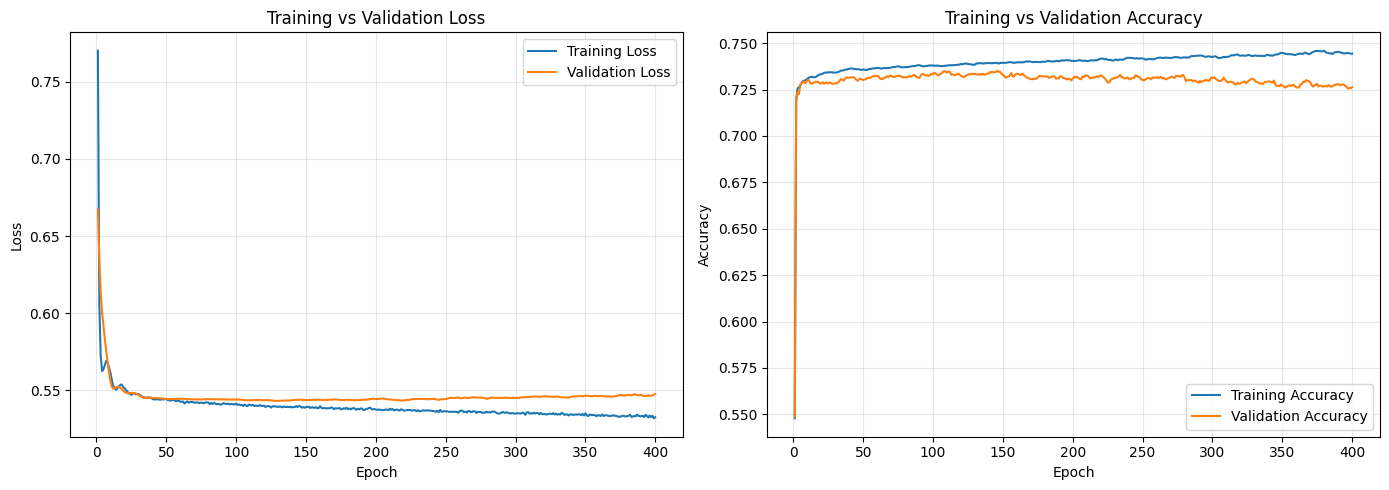

In [47]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "input_dim": 11,
        "dropout": 0.3
    },
    "best_cardiovascular_dnn.pth"
)

print("Best model saved successfully!")

Best model saved successfully!


## Evaluatio part 1 (Validation set)

In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Make sure we use the best model
model.eval()

with torch.no_grad():

    val_outputs = model(X_val_tensor)

    # Predicted classes
    val_predictions = torch.argmax(val_outputs, dim=1)

    # Probability of class 1
    val_probabilities = torch.softmax(
        val_outputs, dim=1
    )[:, 1]

# Move predictions and labels to CPU
y_val_true = y_val_tensor.cpu().numpy()
y_val_pred = val_predictions.cpu().numpy()
y_val_prob = val_probabilities.cpu().numpy()

# Calculate metrics
val_accuracy = accuracy_score(y_val_true, y_val_pred)

val_precision = precision_score(
    y_val_true, y_val_pred, zero_division=0
)

val_recall = recall_score(
    y_val_true, y_val_pred, zero_division=0
)

val_f1 = f1_score(
    y_val_true, y_val_pred, zero_division=0
)

val_auc = roc_auc_score(y_val_true, y_val_prob)

print("Validation Results")
print("------------------------------")
print(f"Accuracy:  {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1-score:  {val_f1:.4f}")
print(f"ROC-AUC:   {val_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=["No Disease (0)", "Disease (1)"],
        zero_division=0
    )
)

Validation Results
------------------------------
Accuracy:  0.7335
Precision: 0.7491
Recall:    0.6812
F1-score:  0.7135
ROC-AUC:   0.8004

Classification Report:
                precision    recall  f1-score   support

No Disease (0)       0.72      0.78      0.75      3518
   Disease (1)       0.75      0.68      0.71      3344

      accuracy                           0.73      6862
     macro avg       0.74      0.73      0.73      6862
  weighted avg       0.73      0.73      0.73      6862



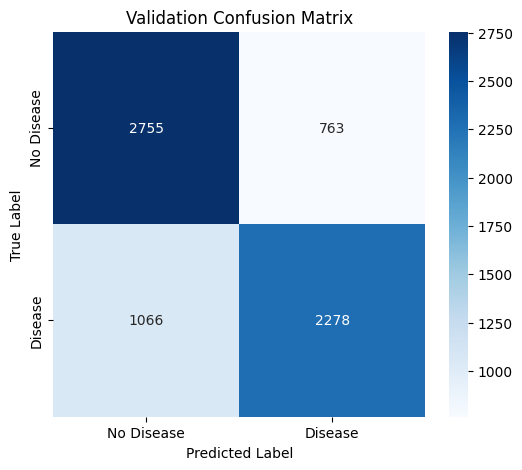

In [50]:
cm = confusion_matrix(y_val_true, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Validation Confusion Matrix")

plt.show()

##Tune Hyperprameters

In [51]:
import copy
import itertools
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

learning_rates = [0.001, 0.005, 0.01]
weight_decays = [0, 0.0001]

MAX_EPOCHS = 400
PATIENCE = 30

tuning_results = []

global_best_val_loss = float("inf")
global_best_state = None
global_best_config = None

for lr, wd in itertools.product(learning_rates, weight_decays):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    # Reset seed to make initialization comparable
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    candidate_model = CardiovascularDNN(
        input_dim=11,
        dropout=0.3
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_config_loss = float("inf")
    best_config_epoch = 0
    best_config_state = None
    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        # Training
        candidate_model.train()

        optimizer.zero_grad()

        train_outputs = candidate_model(X_train_tensor)
        train_loss = criterion(train_outputs, y_train_tensor)

        train_loss.backward()
        optimizer.step()

        # Validation
        candidate_model.eval()

        with torch.no_grad():
            val_outputs = candidate_model(X_val_tensor)

            val_loss = criterion(
                val_outputs,
                y_val_tensor
            ).item()

        # Save best checkpoint for this configuration
        if val_loss < best_config_loss:

            best_config_loss = val_loss
            best_config_epoch = epoch + 1

            best_config_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            break

    tuning_results.append({
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": best_config_epoch,
        "best_val_loss": best_config_loss
    })

    print(
        f"Best Epoch: {best_config_epoch} | "
        f"Best Val Loss: {best_config_loss:.4f}"
    )

    # Update global best configuration
    if best_config_loss < global_best_val_loss:

        global_best_val_loss = best_config_loss

        global_best_state = copy.deepcopy(
            best_config_state
        )

        global_best_config = {
            "learning_rate": lr,
            "weight_decay": wd,
            "best_epoch": best_config_epoch
        }

    del candidate_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Display results
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="best_val_loss"
).reset_index(drop=True)

print("\nHyperparameter Tuning Results:")
display(tuning_df)

print("\nBest Configuration:")
print(global_best_config)
print(f"Best Validation Loss: {global_best_val_loss:.4f}")


Testing LR=0.001, Weight Decay=0
Best Epoch: 247 | Best Val Loss: 0.5445

Testing LR=0.001, Weight Decay=0.0001
Best Epoch: 247 | Best Val Loss: 0.5445

Testing LR=0.005, Weight Decay=0
Best Epoch: 138 | Best Val Loss: 0.5440

Testing LR=0.005, Weight Decay=0.0001
Best Epoch: 111 | Best Val Loss: 0.5448

Testing LR=0.01, Weight Decay=0
Best Epoch: 128 | Best Val Loss: 0.5431

Testing LR=0.01, Weight Decay=0.0001
Best Epoch: 49 | Best Val Loss: 0.5454

Hyperparameter Tuning Results:


,learning_rate,weight_decay,best_epoch,best_val_loss
0,0.010,0.0000,128,0.543087
1,0.005,0.0000,138,0.543958
2,0.001,0.0000,247,0.544486
3,0.001,0.0001,247,0.544516
4,0.005,0.0001,111,0.544846
5,0.010,0.0001,49,0.545366



Best Configuration:
{'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 128}
Best Validation Loss: 0.5431


In [52]:
model = CardiovascularDNN(
    input_dim=11,
    dropout=0.3
).to(device)

model.load_state_dict(global_best_state)
model.eval()

print("Best tuned model loaded successfully!")
print("Configuration:", global_best_config)

Best tuned model loaded successfully!
Configuration: {'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 128}


In [53]:
torch.save({
    "model_state_dict": model.state_dict(),
    "best_config": global_best_config,
    "best_val_loss": global_best_val_loss,
    "input_dim": 11,
    "dropout": 0.3
}, "best_tuned_cardiovascular_dnn.pth")

print("Tuned model saved successfully!")

Tuned model saved successfully!


## Baseline (Shallow MLP)

In [54]:
#================
# Baseline Model Architecture
#================

class CardiovascularShallowMLP(nn.Module):

    def __init__(self, input_dim):
        super(CardiovascularShallowMLP, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)


baseline_model = CardiovascularShallowMLP(
    input_dim=X_train_tensor.shape[1]
).to(device)

print(baseline_model)

baseline_params = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

deep_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable Parameters:")
print("Baseline MLP:", baseline_params)
print("Deep MLP:", deep_params)

CardiovascularShallowMLP(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=2, bias=True)
  )
)

Trainable Parameters:
Baseline MLP: 450
Deep MLP: 12386


In [55]:

#================
# Baseline Model Training & Tuning
#================

baseline_best_train_history = None
baseline_best_val_history = None

learning_rates = [0.001, 0.005, 0.01]
weight_decays = [0, 0.0001]

MAX_EPOCHS = 400
PATIENCE = 30

baseline_tuning_results = []

baseline_best_val_loss = float("inf")
baseline_best_state = None
baseline_best_config = None

criterion = nn.CrossEntropyLoss()

for lr, wd in itertools.product(learning_rates, weight_decays):

    print(f"\nTesting LR={lr}, Weight Decay={wd}")

    # Reset seed for comparable initialization
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    candidate_model = CardiovascularShallowMLP(
        input_dim=X_train_tensor.shape[1]
    ).to(device)

    optimizer = optim.Adam(
        candidate_model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    best_config_loss = float("inf")
    best_config_epoch = 0
    best_config_state = None

    # Track loss for this configuration
    train_history = []
    val_history = []

    patience_counter = 0

    for epoch in range(MAX_EPOCHS):

        # Training
        candidate_model.train()

        optimizer.zero_grad()

        train_outputs = candidate_model(X_train_tensor)

        train_loss = criterion(
            train_outputs,
            y_train_tensor
        )

        train_loss.backward()
        optimizer.step()

        # Validation
        candidate_model.eval()

        with torch.no_grad():

            val_outputs = candidate_model(X_val_tensor)

            val_loss = criterion(
                val_outputs,
                y_val_tensor
            ).item()

        # Record epoch losses
        train_history.append(train_loss.item())
        val_history.append(val_loss)

        # Save best checkpoint
        if val_loss < best_config_loss:

            best_config_loss = val_loss
            best_config_epoch = epoch + 1

            best_config_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            break

    baseline_tuning_results.append({
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": best_config_epoch,
        "best_val_loss": best_config_loss
    })

    print(
        f"Best Epoch: {best_config_epoch} | "
        f"Best Val Loss: {best_config_loss:.4f}"
    )

    # Keep the best configuration and its histories
    if best_config_loss < baseline_best_val_loss:

        baseline_best_val_loss = best_config_loss

        baseline_best_state = copy.deepcopy(
            best_config_state
        )

        baseline_best_train_history = train_history.copy()
        baseline_best_val_history = val_history.copy()

        baseline_best_config = {
            "learning_rate": lr,
            "weight_decay": wd,
            "best_epoch": best_config_epoch
        }

    del candidate_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Display tuning results
baseline_tuning_df = pd.DataFrame(
    baseline_tuning_results
).sort_values(
    by="best_val_loss"
).reset_index(drop=True)

print("\nBaseline Tuning Results:")
display(baseline_tuning_df)

print("\nBest Baseline Configuration:")
print(baseline_best_config)

print(f"Best Validation Loss: {baseline_best_val_loss:.4f}")



Testing LR=0.001, Weight Decay=0
Best Epoch: 400 | Best Val Loss: 0.5525

Testing LR=0.001, Weight Decay=0.0001
Best Epoch: 400 | Best Val Loss: 0.5520

Testing LR=0.005, Weight Decay=0
Best Epoch: 326 | Best Val Loss: 0.5457

Testing LR=0.005, Weight Decay=0.0001
Best Epoch: 334 | Best Val Loss: 0.5451

Testing LR=0.01, Weight Decay=0
Best Epoch: 394 | Best Val Loss: 0.5443

Testing LR=0.01, Weight Decay=0.0001
Best Epoch: 214 | Best Val Loss: 0.5444

Baseline Tuning Results:


,learning_rate,weight_decay,best_epoch,best_val_loss
0,0.010,0.0000,394,0.544263
1,0.010,0.0001,214,0.544447
2,0.005,0.0001,334,0.545121
3,0.005,0.0000,326,0.545688
4,0.001,0.0001,400,0.551973
5,0.001,0.0000,400,0.552505



Best Baseline Configuration:
{'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 394}
Best Validation Loss: 0.5443


In [56]:
#================
# Load Best Baseline Model
#================

baseline_model = CardiovascularShallowMLP(
    input_dim=X_train_tensor.shape[1]
).to(device)

baseline_model.load_state_dict(baseline_best_state)

baseline_model.eval()

print("Best baseline model loaded successfully!")
print("Configuration:", baseline_best_config)

Best baseline model loaded successfully!
Configuration: {'learning_rate': 0.01, 'weight_decay': 0, 'best_epoch': 394}


## Evaluation

In [57]:
#================
# Final Test Evaluation — Model Comparison
#================

model.eval()
baseline_model.eval()

with torch.no_grad():

    # Deep MLP
    deep_outputs = model(X_test_tensor)

    deep_probabilities = torch.softmax(
        deep_outputs, dim=1
    )[:, 1]

    deep_predictions = torch.argmax(
        deep_outputs, dim=1
    )

    # Shallow MLP baseline
    baseline_outputs = baseline_model(X_test_tensor)

    baseline_probabilities = torch.softmax(
        baseline_outputs, dim=1
    )[:, 1]

    baseline_predictions = torch.argmax(
        baseline_outputs, dim=1
    )


# Convert to NumPy
y_test_true = y_test_tensor.cpu().numpy()

deep_pred = deep_predictions.cpu().numpy()
deep_prob = deep_probabilities.cpu().numpy()

baseline_pred = baseline_predictions.cpu().numpy()
baseline_prob = baseline_probabilities.cpu().numpy()


# Calculate metrics
def calculate_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


deep_test_metrics = calculate_metrics(
    y_test_true, deep_pred, deep_prob
)

baseline_test_metrics = calculate_metrics(
    y_test_true, baseline_pred, baseline_prob
)


# Comparison table
comparison = pd.DataFrame({
    "Metric": list(deep_test_metrics.keys()),
    "Shallow MLP Baseline": list(baseline_test_metrics.values()),
    "Deep MLP": list(deep_test_metrics.values())
})

comparison["Difference"] = (
    comparison["Deep MLP"] -
    comparison["Shallow MLP Baseline"]
)

print("FINAL TEST RESULTS")
print("=" * 55)

display(comparison.round(4))

FINAL TEST RESULTS


,Metric,Shallow MLP Baseline,Deep MLP,Difference
0,Accuracy,0.7367,0.7390,0.0023
1,Precision,0.7551,0.7566,0.0014
2,Recall,0.6866,0.6910,0.0045
3,F1-score,0.7192,0.7223,0.0031
4,ROC-AUC,0.8032,0.8035,0.0003


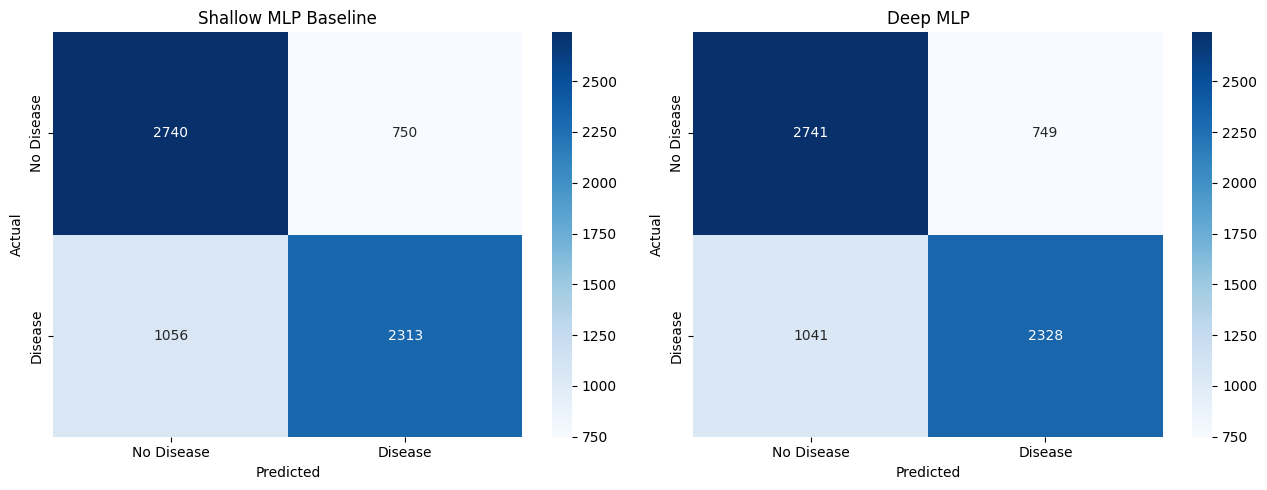

In [58]:
#================
# Confusion Matrix Comparison
#================

baseline_cm = confusion_matrix(
    y_test_true, baseline_pred
)

deep_cm = confusion_matrix(
    y_test_true, deep_pred
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"],
    ax=axes[0]
)

axes[0].set_title("Shallow MLP Baseline")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    deep_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"],
    ax=axes[1]
)

axes[1].set_title("Deep MLP")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

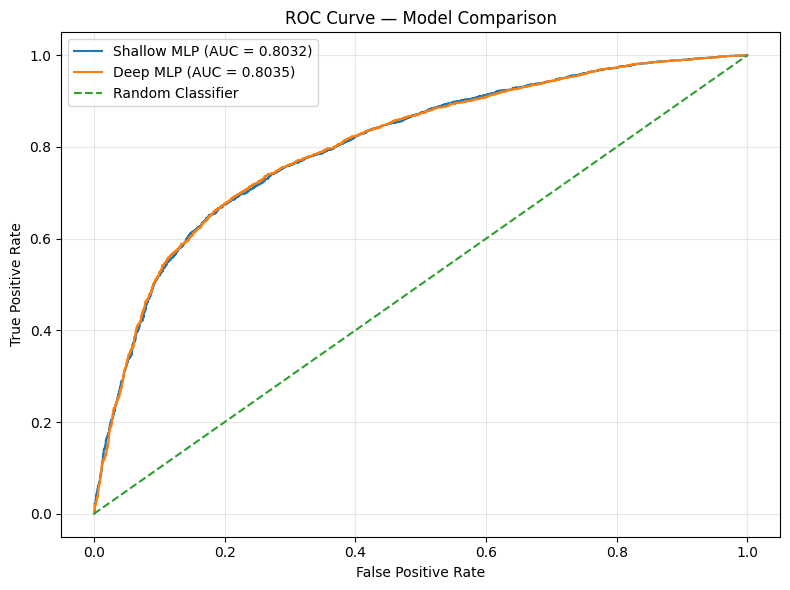

In [59]:
#================
# ROC Curve Comparison
#================

baseline_fpr, baseline_tpr, _ = roc_curve(
    y_test_true, baseline_prob
)

deep_fpr, deep_tpr, _ = roc_curve(
    y_test_true, deep_prob
)

baseline_auc = roc_auc_score(
    y_test_true, baseline_prob
)

deep_auc = roc_auc_score(
    y_test_true, deep_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f"Shallow MLP (AUC = {baseline_auc:.4f})"
)

plt.plot(
    deep_fpr,
    deep_tpr,
    label=f"Deep MLP (AUC = {deep_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Bonus Part: Improving the Paper's MLP

Everything above this section (EDA, cleaning, grouped split, original Deep MLP, Shallow MLP baseline, and their test evaluation) is kept unchanged as the reference. Everything below is new.

**Protocol (follows the project guidelines, Section 9 "Bonus")**

| Requirement | How it is satisfied |
|---|---|
| Compare modified vs. original on the *same data and split* | One split, created once in *Data Splitting*; every model below uses the same rows. Only seeds change (initialisation, dropout, batch order). |
| Choose the change using the validation set only | Every design decision (features, architecture, optimiser recipe, logistic-regression `C`, decision threshold) is made on validation data. Candidate selection uses its own seeds (`0, 1, 2`). |
| Use the test set only once | Test tensors are not touched until the cell *Final Test Evaluation (single use of the test set)*. |
| Run each model 3 times with different seeds, report the average | `FINAL_SEEDS = [42, 123, 2024]`; tables show mean ± std. |
| Explain what changed and why it helped, with and without the change | *Candidate Selection* is an ablation ladder; *Discussion* summarises it. |
| Beating the paper itself | **Not claimed.** The guidelines require running both models on the paper's own dataset for that claim; all comparisons here are on the new dataset only. |

**Selection rule (declared before any candidate is trained):** pick the candidate with the lowest mean validation log-loss over the 3 selection seeds. If several candidates are within `0.0005` of the best, pick the one with the fewest parameters.

## Bonus Setup

In [60]:
#================
# Bonus Setup: imports, seeds, helpers
#================
import json
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss

SELECTION_SEEDS = [0, 1, 2]        # used only to compare candidates on validation data
FINAL_SEEDS = [42, 123, 2024]      # used for the final original-vs-modified comparison


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def predict_proba_torch(net, X):
    net.eval()
    with torch.no_grad():
        return torch.softmax(net(X), dim=1)[:, 1].cpu().numpy()


def bonus_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }


# Frozen reference configuration of the ORIGINAL model (taken from the tuning above)
ORIGINAL_CONFIG = {
    "learning_rate": global_best_config["learning_rate"],
    "weight_decay": global_best_config["weight_decay"],
    "dropout": 0.3,
    "max_epochs": 400,
    "patience": 30,
}
SHALLOW_CONFIG = {
    "learning_rate": baseline_best_config["learning_rate"],
    "weight_decay": baseline_best_config["weight_decay"],
    "max_epochs": 400,
    "patience": 30,
}
print("Original Deep MLP config:", ORIGINAL_CONFIG)
print("Shallow MLP config:      ", SHALLOW_CONFIG)

Original Deep MLP config: {'learning_rate': 0.01, 'weight_decay': 0, 'dropout': 0.3, 'max_epochs': 400, 'patience': 30}
Shallow MLP config:       {'learning_rate': 0.01, 'weight_decay': 0, 'max_epochs': 400, 'patience': 30}


## Baseline: Logistic Regression

The uploaded notebook did not contain a Logistic Regression experiment, so it is added here as a linear reference on the same split and the same standardised features. Its only hyper-parameter (`C`) is chosen on the validation set. It is evaluated on the test set later, together with all other models.

In [61]:
#================
# Logistic Regression: tune C on validation data
#================
logreg_rows = []
logreg_models = {}

for C in [0.01, 0.1, 1, 10, 100]:
    lr_model = LogisticRegression(C=C, max_iter=2000)
    lr_model.fit(X_train_np, y_train_np)
    p_val = lr_model.predict_proba(X_val_np)[:, 1]
    logreg_models[C] = lr_model
    logreg_rows.append({
        "C": C,
        "val_log_loss": log_loss(y_val_np, p_val),
        "val_auc": roc_auc_score(y_val_np, p_val),
        "val_accuracy": accuracy_score(y_val_np, p_val >= 0.5),
    })

logreg_df = pd.DataFrame(logreg_rows).sort_values("val_log_loss").reset_index(drop=True)
display(logreg_df.round(4))

LOGREG_C = float(logreg_df.loc[0, "C"])
logreg_final = logreg_models[LOGREG_C]
print("Selected C (validation log-loss):", LOGREG_C)

,C,val_log_loss,val_auc,val_accuracy
0,0.01,0.5643,0.7903,0.7259
1,0.10,0.5643,0.7904,0.7263
2,1.00,0.5643,0.7904,0.7262
3,10.00,0.5643,0.7904,0.7262
4,100.00,0.5643,0.7904,0.7262


Selected C (validation log-loss): 0.01


## Bottleneck Investigation (validation data only)

Before changing the architecture we test *why* Logistic Regression, the Shallow MLP and the Deep MLP are all so close. Four hypotheses:

1. **Model capacity is the limit** → compare against a much more flexible learner (gradient boosting) used purely as a diagnostic.
2. **Not enough data** → learning curves.
3. **The signal is concentrated in a few features** → permutation importance and cumulative feature sets.
4. **Class imbalance** → check the class ratio and the precision/recall gap.

Gradient boosting is *not* a course topic and is *not* proposed as the project model. It is only a probe of how much signal these 11 features contain.

In [62]:
#================
# H1: Does a far more flexible learner do better? (validation set)
#================
hgb_probe = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, max_depth=4, random_state=42
).fit(X_train_np, y_train_np)

val_probs = {
    "Logistic Regression": logreg_final.predict_proba(X_val_np)[:, 1],
    "Shallow MLP (450 params)": predict_proba_torch(baseline_model, X_val_tensor),
    "Deep MLP (original)": predict_proba_torch(model, X_val_tensor),
    "Gradient boosting (probe only)": hgb_probe.predict_proba(X_val_np)[:, 1],
}

rows = []
for name, p in val_probs.items():
    rows.append({
        "Model": name,
        "Val ROC-AUC": roc_auc_score(y_val_np, p),
        "Val Accuracy": accuracy_score(y_val_np, p >= 0.5),
        "Val Log-loss": log_loss(y_val_np, p),
    })

capacity_df = pd.DataFrame(rows)
display(capacity_df.round(4))
print("Spread of validation ROC-AUC across all four learners:",
      round(capacity_df["Val ROC-AUC"].max() - capacity_df["Val ROC-AUC"].min(), 4))

,Model,Val ROC-AUC,Val Accuracy,Val Log-loss
0,Logistic Regression,0.7903,0.7259,0.5643
1,Shallow MLP (450 params),0.7989,0.7324,0.5443
2,Deep MLP (original),0.8004,0.7335,0.5431
3,Gradient boosting (probe only),0.7988,0.7321,0.5442


Spread of validation ROC-AUC across all four learners: 0.0101


,n_train,Logistic Regression,Gradient boosting
0,2744,0.7876,0.7813
1,5488,0.7891,0.7903
2,13722,0.7897,0.7973
3,27444,0.7900,0.7982
4,54889,0.7903,0.7991


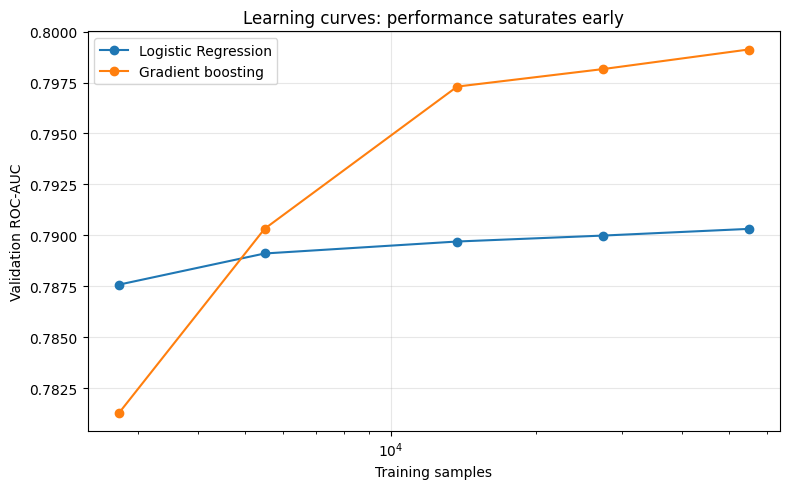

In [63]:
#================
# H2: Learning curves (validation ROC-AUC vs. training-set size)
#================
fractions = [0.05, 0.1, 0.25, 0.5, 1.0]
rng = np.random.RandomState(0)
order = rng.permutation(len(X_train_np))

lc_rows = []
for frac in fractions:
    idx = order[: int(len(order) * frac)]
    lr_m = LogisticRegression(C=LOGREG_C, max_iter=2000).fit(X_train_np[idx], y_train_np[idx])
    gb_m = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_depth=4, random_state=42
    ).fit(X_train_np[idx], y_train_np[idx])
    lc_rows.append({
        "n_train": len(idx),
        "Logistic Regression": roc_auc_score(y_val_np, lr_m.predict_proba(X_val_np)[:, 1]),
        "Gradient boosting": roc_auc_score(y_val_np, gb_m.predict_proba(X_val_np)[:, 1]),
    })

lc_df = pd.DataFrame(lc_rows)
display(lc_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(lc_df["n_train"], lc_df["Logistic Regression"], marker="o", label="Logistic Regression")
plt.plot(lc_df["n_train"], lc_df["Gradient boosting"], marker="o", label="Gradient boosting")
plt.xscale("log")
plt.xlabel("Training samples")
plt.ylabel("Validation ROC-AUC")
plt.title("Learning curves: performance saturates early")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

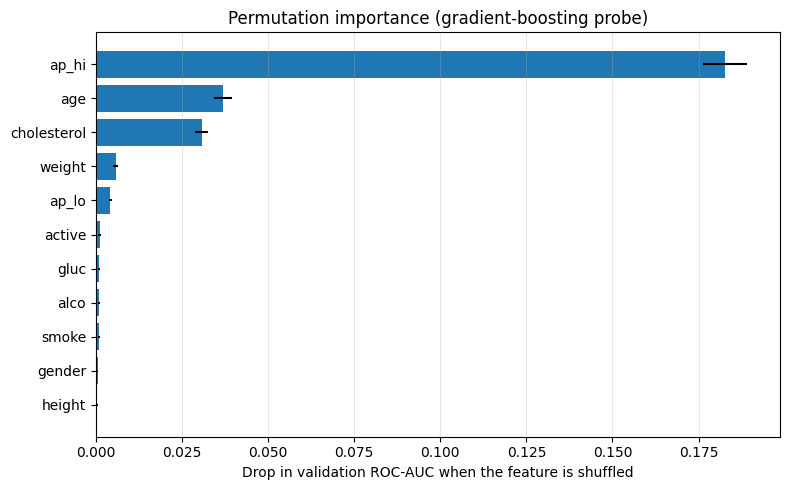

,features,n_features,val_auc
0,ap_hi,1,0.7490
1,"ap_hi, ap_lo",2,0.7506
2,"ap_hi, ap_lo, age",3,0.7809
3,"ap_hi, ap_lo, age, cholesterol",4,0.7943
4,"ap_hi, ap_lo, age, cholesterol, weight",5,0.7957
5,all 11 features,11,0.7981


In [64]:
#================
# H3: Where is the signal? (validation set only)
#================
feature_names = X_train.columns.tolist()

perm = permutation_importance(
    hgb_probe, X_val_np, y_val_np,
    scoring="roc_auc", n_repeats=5, random_state=42
)
perm_df = pd.DataFrame({
    "feature": feature_names,
    "auc_drop": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("auc_drop", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(perm_df["feature"], perm_df["auc_drop"], xerr=perm_df["std"])
plt.xlabel("Drop in validation ROC-AUC when the feature is shuffled")
plt.title("Permutation importance (gradient-boosting probe)")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

cumulative_sets = [
    ["ap_hi"],
    ["ap_hi", "ap_lo"],
    ["ap_hi", "ap_lo", "age"],
    ["ap_hi", "ap_lo", "age", "cholesterol"],
    ["ap_hi", "ap_lo", "age", "cholesterol", "weight"],
    feature_names,
]
cum_rows = []
for cols in cumulative_sets:
    gb = HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_depth=3, random_state=42
    ).fit(X_train[cols].to_numpy(), y_train_np)
    cum_rows.append({
        "features": ", ".join(cols) if len(cols) < 11 else "all 11 features",
        "n_features": len(cols),
        "val_auc": roc_auc_score(y_val_np, gb.predict_proba(X_val[cols].to_numpy())[:, 1]),
    })
display(pd.DataFrame(cum_rows).round(4))

In [65]:
#================
# H4: Class imbalance? Precision / recall gap
#================
print("Class balance (share of 'Disease'):")
for name, target in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"  {name:11s}: {target.mean() * 100:.2f}%")

p_deep_val = val_probs["Deep MLP (original)"]
print("\nDeep MLP on validation data at threshold 0.5:")
print("  Precision:", round(precision_score(y_val_np, p_deep_val >= 0.5), 4))
print("  Recall:   ", round(recall_score(y_val_np, p_deep_val >= 0.5), 4))
print("  Mean predicted P(disease):", round(p_deep_val.mean(), 4),
      "| true prevalence:", round(y_val_np.mean(), 4))

Class balance (share of 'Disease'):
  Train      : 49.61%
  Validation : 48.73%
  Test       : 49.12%

Deep MLP on validation data at threshold 0.5:
  Precision: 0.7491
  Recall:    0.6812
  Mean predicted P(disease): 0.4927 | true prevalence: 0.4873


### Findings of the investigation

* **Capacity is not the bottleneck.** A far more flexible learner reaches almost the same validation ROC-AUC as Logistic Regression and both MLPs; the whole spread is on the order of 0.01 AUC.
* **Data quantity is not the bottleneck.** Learning curves are flat well before the full training set is used, so more samples of the same kind would not help.
* **The signal is concentrated and coarse.** Systolic blood pressure, age and cholesterol carry nearly all of it; height, gender, smoking, alcohol, glucose and activity add almost nothing. Systolic BP alone already reaches roughly 0.75 AUC.
* **Class imbalance does not apply.** The classes are balanced (~49.5% / 50.5%), so class re-weighting or resampling is not justified. The recall < precision gap is a decision-threshold effect, not an imbalance effect; it is examined with a validation-selected threshold below.
* **Irreducible overlap.** The 11 features are coarse (self-reported habits, three-level cholesterol/glucose codes, single blood-pressure readings). Patients with identical features can have different outcomes (see the label-conflict check in *Data Splitting*). A performance ceiling near 0.80 AUC / 0.74 accuracy is therefore a property of the data, and we should expect any modification to produce small gains at best.

Consequently, the modifications below target what *can* still matter: the input representation, the optimisation recipe (the original uses 400 full-batch steps), and parameter efficiency / regularisation.

## Feature Engineering (fit on training data only)

All engineered features are deterministic functions of the raw row (clinically motivated formulas with fixed thresholds), so they cannot leak information. The only learned quantity is the standardisation, which is fitted on the training split.

| Feature | Motivation |
|---|---|
| `bmi = weight / height²` | Combines two weakly informative variables into the standard obesity indicator. |
| `pulse_pressure = ap_hi − ap_lo`, `map = ap_lo + pp/3` | Standard haemodynamic quantities; a network would need to learn these differences itself. |
| `log_ap_hi`, `log_ap_lo` | Blood pressure is right-skewed; the log reduces the influence of the high tail. |
| `male`, `cholesterol_2/3`, `gluc_2/3` | One-hot encoding for categorical codes that were previously fed as ordinal numbers. The original ordinal columns are kept as well. |
| `bp_stage` (level `full` only) | ACC/AHA blood-pressure category (0 normal … 3 stage-2 hypertension) from fixed clinical thresholds. |

In [66]:
#================
# Feature engineering and representations
#================
RAW_ALL = df_clean.drop(columns="cardio")      # unscaled features, same row index as X
NUMERIC_FE = ["age", "height", "weight", "ap_hi", "ap_lo",
              "bmi", "pulse_pressure", "map", "log_ap_hi", "log_ap_lo"]


def engineer(raw, level):
    d = raw.copy().astype(float)
    d["bmi"] = d["weight"] / (d["height"] / 100) ** 2
    d["pulse_pressure"] = d["ap_hi"] - d["ap_lo"]
    d["map"] = d["ap_lo"] + d["pulse_pressure"] / 3
    d["log_ap_hi"] = np.log(d["ap_hi"])
    d["log_ap_lo"] = np.log(d["ap_lo"])
    d["male"] = (d["gender"] == 2).astype(float)
    d = d.drop(columns="gender")
    for col in ["cholesterol", "gluc"]:
        for v in (2, 3):
            d[f"{col}_{v}"] = (d[col] == v).astype(float)
    if level == "full":
        d["bp_stage"] = np.select(
            [(d["ap_hi"] >= 140) | (d["ap_lo"] >= 90),
             (d["ap_hi"] >= 130) | (d["ap_lo"] >= 80),
             (d["ap_hi"] >= 120)],
            [3, 2, 1], default=0
        ).astype(float)
    return d


def make_representation(level):
    parts = {
        "train": engineer(RAW_ALL.loc[X_train.index], level),
        "val": engineer(RAW_ALL.loc[X_val.index], level),
        "test": engineer(RAW_ALL.loc[X_test.index], level),
    }
    sc = StandardScaler().fit(parts["train"][NUMERIC_FE])          # TRAIN ONLY
    out = {}
    for split, d in parts.items():
        d = d.copy()
        d[NUMERIC_FE] = sc.transform(d[NUMERIC_FE])
        out[split] = torch.tensor(d.to_numpy(dtype=np.float32)).to(device)
    out["columns"] = parts["train"].columns.tolist()
    return out


REPS = {
    "raw": {"train": X_train_tensor, "val": X_val_tensor, "test": X_test_tensor,
            "columns": X_train.columns.tolist()},      # representation of the original model
    "basic": make_representation("basic"),
    "full": make_representation("full"),
}
Y = {"train": y_train_tensor, "val": y_val_tensor, "test": y_test_tensor}

for name, r in REPS.items():
    print(f"{name:6s} -> {r['train'].shape[1]} features")
print("\nFull representation columns:\n", REPS["full"]["columns"])

raw    -> 11 features
basic  -> 20 features
full   -> 21 features

Full representation columns:
 ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi', 'pulse_pressure', 'map', 'log_ap_hi', 'log_ap_lo', 'male', 'cholesterol_2', 'cholesterol_3', 'gluc_2', 'gluc_3', 'bp_stage']


## Training Recipes and Architectures

Two training recipes are implemented:

* **Original recipe** (reference): full-batch Adam, learning rate / weight decay from the tuning above, early stopping on validation loss (patience 30, at most 400 epochs). This is exactly the protocol of the existing notebook, wrapped in a function so it can be repeated for several seeds.
* **Mini-batch recipe**: AdamW, batch size 512, `ReduceLROnPlateau` on validation loss, early stopping (patience 15). Motivation: full-batch training gives only 400 gradient steps (the Shallow MLP was still improving at epoch 394 of 400); mini-batches give about 100 updates per epoch and add helpful gradient noise.

The original `CardiovascularDNN` class is **not modified**. New architectures are separate classes.

In [67]:
#================
# Training functions
#================
def _evaluate(net, X, y, criterion):
    net.eval()
    with torch.no_grad():
        out = net(X)
        loss = criterion(out, y).item()
        acc = (out.argmax(dim=1) == y).float().mean().item()
    return loss, acc


def _new_history():
    return {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}


def train_original_recipe(net, rep, lr, wd, max_epochs=400, patience=30):
    # Full-batch Adam with early stopping on validation loss (same protocol as the tuning cell)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    hist, best_loss, best_epoch, best_state, wait = _new_history(), float("inf"), 0, None, 0

    for epoch in range(max_epochs):
        net.train()
        optimizer.zero_grad()
        loss = criterion(net(rep["train"]), Y["train"])
        loss.backward()
        optimizer.step()

        _, tr_acc = _evaluate(net, rep["train"], Y["train"], criterion)
        v_loss, v_acc = _evaluate(net, rep["val"], Y["val"], criterion)
        hist["train_loss"].append(loss.item()); hist["train_accuracy"].append(tr_acc)
        hist["val_loss"].append(v_loss);        hist["val_accuracy"].append(v_acc)

        if v_loss < best_loss:
            best_loss, best_epoch, wait = v_loss, epoch + 1, 0
            best_state = copy.deepcopy(net.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break

    net.load_state_dict(best_state)
    return {"history": hist, "best_epoch": best_epoch, "best_val_loss": best_loss}


def train_minibatch_recipe(net, rep, lr=1e-3, wd=1e-4, max_epochs=100,
                           batch_size=512, patience=15):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=4)
    n = len(rep["train"])
    hist, best_loss, best_epoch, best_state, wait = _new_history(), float("inf"), 0, None, 0

    for epoch in range(max_epochs):
        net.train()
        perm = torch.randperm(n, device=rep["train"].device)
        running, seen = 0.0, 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:                      # BatchNorm needs > 1 sample
                continue
            optimizer.zero_grad()
            loss = criterion(net(rep["train"][idx]), Y["train"][idx])
            loss.backward()
            optimizer.step()
            running += loss.item() * len(idx); seen += len(idx)

        _, tr_acc = _evaluate(net, rep["train"], Y["train"], criterion)
        v_loss, v_acc = _evaluate(net, rep["val"], Y["val"], criterion)
        scheduler.step(v_loss)
        hist["train_loss"].append(running / seen); hist["train_accuracy"].append(tr_acc)
        hist["val_loss"].append(v_loss);           hist["val_accuracy"].append(v_acc)

        if v_loss < best_loss - 1e-5:
            best_loss, best_epoch, wait = v_loss, epoch + 1, 0
            best_state = copy.deepcopy(net.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break

    net.load_state_dict(best_state)
    return {"history": hist, "best_epoch": best_epoch, "best_val_loss": best_loss}


def count_params(net):
    return sum(p.numel() for p in net.parameters() if p.requires_grad)

In [68]:
#================
# New architectures (the original CardiovascularDNN above is left untouched)
#================
class ConfigurableMLP(nn.Module):
    # Hidden stack of Linear -> Norm -> Activation -> Dropout blocks
    def __init__(self, input_dim, hidden=(64, 32), dropout=0.2,
                 activation=nn.ReLU, norm="batch"):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.BatchNorm1d(h) if norm == "batch" else nn.LayerNorm(h))
            layers.append(activation())
            layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 2))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


class ResidualMLP(nn.Module):
    # Pre-norm residual blocks: skip connections keep a direct linear path for the strong linear signal
    def __init__(self, input_dim, width=64, n_blocks=2, dropout=0.2):
        super().__init__()
        self.inp = nn.Linear(input_dim, width)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(width), nn.Linear(width, width), nn.SiLU(),
                          nn.Dropout(dropout), nn.Linear(width, width))
            for _ in range(n_blocks)
        ])
        self.out = nn.Sequential(nn.LayerNorm(width), nn.SiLU(), nn.Linear(width, 2))

    def forward(self, x):
        z = self.inp(x)
        for block in self.blocks:
            z = z + block(z)
        return self.out(z)

## Candidate Selection (validation data only)

The candidates form an **ablation ladder**: A1→A3 isolate the effect of the training recipe and of the features while keeping the original architecture; C1→C5 then change the architecture on the best representation. Each candidate is trained with the 3 selection seeds; the test set is not used.

In [69]:
#================
# Candidate selection on the validation set
#================
CANDIDATES = [
    {"name": "A1 raw features + original arch + mini-batch",   "rep": "raw",   "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: CardiovascularDNN(d, 0.3)},
    {"name": "A2 basic features + original arch",              "rep": "basic", "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: CardiovascularDNN(d, 0.3)},
    {"name": "A3 full features + original arch",               "rep": "full",  "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: CardiovascularDNN(d, 0.3)},
    {"name": "C1 full + compact 64-32 (dropout 0.2)",          "rep": "full",  "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: ConfigurableMLP(d, (64, 32), 0.2)},
    {"name": "C2 full + tiny 32-16 (dropout 0.1)",             "rep": "full",  "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: ConfigurableMLP(d, (32, 16), 0.1)},
    {"name": "C3 full + residual 64x2",                        "rep": "full",  "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: ResidualMLP(d, 64, 2, 0.2)},
    {"name": "C4 full + 128-64-32 SiLU/LayerNorm",             "rep": "full",  "recipe": dict(lr=1e-3, wd=1e-4),
     "build": lambda d: ConfigurableMLP(d, (128, 64, 32), 0.2, nn.SiLU, "layer")},
    {"name": "C5 full + compact 64-32, strong weight decay",   "rep": "full",  "recipe": dict(lr=1e-3, wd=1e-2),
     "build": lambda d: ConfigurableMLP(d, (64, 32), 0.2)},
]

selection_rows = []
for cand in CANDIDATES:
    rep = REPS[cand["rep"]]
    runs = []
    for seed in SELECTION_SEEDS:
        set_seed(seed)
        net = cand["build"](rep["train"].shape[1]).to(device)
        info = train_minibatch_recipe(net, rep, **cand["recipe"])
        p_val = predict_proba_torch(net, rep["val"])
        runs.append((info["best_val_loss"], roc_auc_score(y_val_np, p_val),
                     accuracy_score(y_val_np, p_val >= 0.5), info["best_epoch"]))
        n_params = count_params(net)
    runs = np.array(runs)
    selection_rows.append({
        "candidate": cand["name"], "params": n_params,
        "val_loss_mean": runs[:, 0].mean(), "val_loss_std": runs[:, 0].std(),
        "val_auc_mean": runs[:, 1].mean(), "val_acc_mean": runs[:, 2].mean(),
        "best_epoch_mean": runs[:, 3].mean(),
    })
    print(f"{cand['name']:50s} val loss {runs[:, 0].mean():.4f} | AUC {runs[:, 1].mean():.4f} | params {n_params}")

selection_df = pd.DataFrame(selection_rows).sort_values("val_loss_mean").reset_index(drop=True)
display(selection_df.round(4))

A1 raw features + original arch + mini-batch       val loss 0.5433 | AUC 0.8000 | params 12386
A2 basic features + original arch                  val loss 0.5432 | AUC 0.8000 | params 13538
A3 full features + original arch                   val loss 0.5431 | AUC 0.8001 | params 13666
C1 full + compact 64-32 (dropout 0.2)              val loss 0.5427 | AUC 0.8001 | params 3746
C2 full + tiny 32-16 (dropout 0.1)                 val loss 0.5431 | AUC 0.7998 | params 1362
C3 full + residual 64x2                            val loss 0.5423 | AUC 0.8002 | params 18562
C4 full + 128-64-32 SiLU/LayerNorm                 val loss 0.5423 | AUC 0.8002 | params 13666
C5 full + compact 64-32, strong weight decay       val loss 0.5426 | AUC 0.8001 | params 3746


,candidate,params,val_loss_mean,val_loss_std,val_auc_mean,val_acc_mean,best_epoch_mean
0,C4 full + 128-64-32 SiLU/LayerNorm,13666,0.5423,0.0002,0.8002,0.7328,17.6667
1,C3 full + residual 64x2,18562,0.5423,0.0001,0.8002,0.7328,9.3333
2,"C5 full + compact 64-32, strong weight decay",3746,0.5426,0.0003,0.8001,0.7331,26.3333
3,C1 full + compact 64-32 (dropout 0.2),3746,0.5427,0.0002,0.8001,0.7335,26.3333
4,A3 full features + original arch,13666,0.5431,0.0004,0.8001,0.7339,17.0000
5,C2 full + tiny 32-16 (dropout 0.1),1362,0.5431,0.0003,0.7998,0.7330,31.6667
6,A2 basic features + original arch,13538,0.5432,0.0003,0.8000,0.7324,24.3333
7,A1 raw features + original arch + mini-batch,12386,0.5433,0.0004,0.8000,0.7315,30.6667


Best mean validation loss: 0.5423
Candidates within tolerance:


,candidate,params,val_loss_mean,val_auc_mean
0,C4 full + 128-64-32 SiLU/LayerNorm,13666,0.5423,0.8002
1,C3 full + residual 64x2,18562,0.5423,0.8002
2,"C5 full + compact 64-32, strong weight decay",3746,0.5426,0.8001
3,C1 full + compact 64-32 (dropout 0.2),3746,0.5427,0.8001


SELECTED MODIFIED MODEL: C1 full + compact 64-32 (dropout 0.2)
Representation: full | recipe: {'lr': 0.001, 'wd': 0.0001} | parameters: 3746


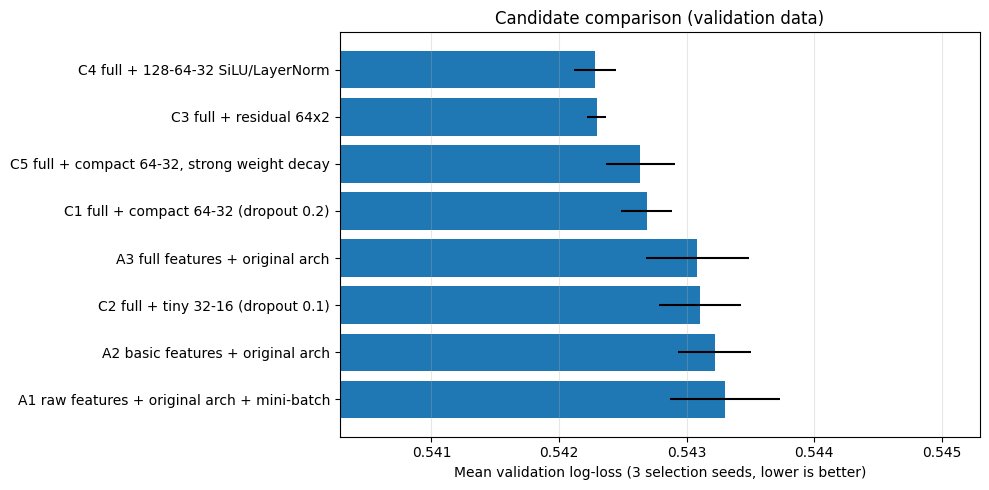

In [70]:
#================
# Apply the pre-declared selection rule
#================
TOLERANCE = 0.0005
best_loss = selection_df["val_loss_mean"].min()
eligible = selection_df[selection_df["val_loss_mean"] <= best_loss + TOLERANCE]
selected_row = eligible.sort_values("params").iloc[0]
SELECTED = next(c for c in CANDIDATES if c["name"] == selected_row["candidate"])

print("Best mean validation loss:", round(best_loss, 4))
print("Candidates within tolerance:")
display(eligible[["candidate", "params", "val_loss_mean", "val_auc_mean"]].round(4))
print("SELECTED MODIFIED MODEL:", SELECTED["name"])
print("Representation:", SELECTED["rep"], "| recipe:", SELECTED["recipe"], "| parameters:", int(selected_row["params"]))

plt.figure(figsize=(10, 5))
order_df = selection_df.sort_values("val_loss_mean", ascending=False)
plt.barh(order_df["candidate"], order_df["val_loss_mean"], xerr=order_df["val_loss_std"])
plt.xlim(order_df["val_loss_mean"].min() - 0.002, order_df["val_loss_mean"].max() + 0.002)
plt.xlabel("Mean validation log-loss (3 selection seeds, lower is better)")
plt.title("Candidate comparison (validation data)")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## Final Training: Original vs. Modified (3 seeds each)

Same split, same data; only the seed changes. Training uses the validation set for early stopping only. The Shallow MLP is also repeated for 3 seeds so the final table is consistent. Nothing here touches the test set.

In [71]:
#================
# Final training: 3 seeds each (validation used for early stopping only)
#================
final = {"Original Deep MLP": {}, "Modified MLP": {}, "Shallow MLP": {}}

for seed in FINAL_SEEDS:
    # Original (reference): original architecture, raw features, original recipe
    set_seed(seed)
    net = CardiovascularDNN(REPS["raw"]["train"].shape[1], ORIGINAL_CONFIG["dropout"]).to(device)
    info = train_original_recipe(net, REPS["raw"], ORIGINAL_CONFIG["learning_rate"],
                                 ORIGINAL_CONFIG["weight_decay"],
                                 ORIGINAL_CONFIG["max_epochs"], ORIGINAL_CONFIG["patience"])
    final["Original Deep MLP"][seed] = {"net": net, "rep": "raw", **info}

    # Shallow MLP baseline (existing protocol)
    set_seed(seed)
    net = CardiovascularShallowMLP(REPS["raw"]["train"].shape[1]).to(device)
    info = train_original_recipe(net, REPS["raw"], SHALLOW_CONFIG["learning_rate"],
                                 SHALLOW_CONFIG["weight_decay"],
                                 SHALLOW_CONFIG["max_epochs"], SHALLOW_CONFIG["patience"])
    final["Shallow MLP"][seed] = {"net": net, "rep": "raw", **info}

    # Modified model (selected on validation data)
    set_seed(seed)
    rep = REPS[SELECTED["rep"]]
    net = SELECTED["build"](rep["train"].shape[1]).to(device)
    info = train_minibatch_recipe(net, rep, **SELECTED["recipe"])
    final["Modified MLP"][seed] = {"net": net, "rep": SELECTED["rep"], **info}

    print(f"seed {seed}: " + " | ".join(
        f"{k}: best epoch {final[k][seed]['best_epoch']}, val loss {final[k][seed]['best_val_loss']:.4f}"
        for k in final))

print("\nParameters:", {k: count_params(v[FINAL_SEEDS[0]]["net"]) for k, v in final.items()})

seed 42: Original Deep MLP: best epoch 128, val loss 0.5431 | Modified MLP: best epoch 42, val loss 0.5420 | Shallow MLP: best epoch 394, val loss 0.5443
seed 123: Original Deep MLP: best epoch 102, val loss 0.5441 | Modified MLP: best epoch 30, val loss 0.5428 | Shallow MLP: best epoch 280, val loss 0.5450
seed 2024: Original Deep MLP: best epoch 98, val loss 0.5441 | Modified MLP: best epoch 20, val loss 0.5423 | Shallow MLP: best epoch 220, val loss 0.5435

Parameters: {'Original Deep MLP': 12386, 'Modified MLP': 3746, 'Shallow MLP': 450}


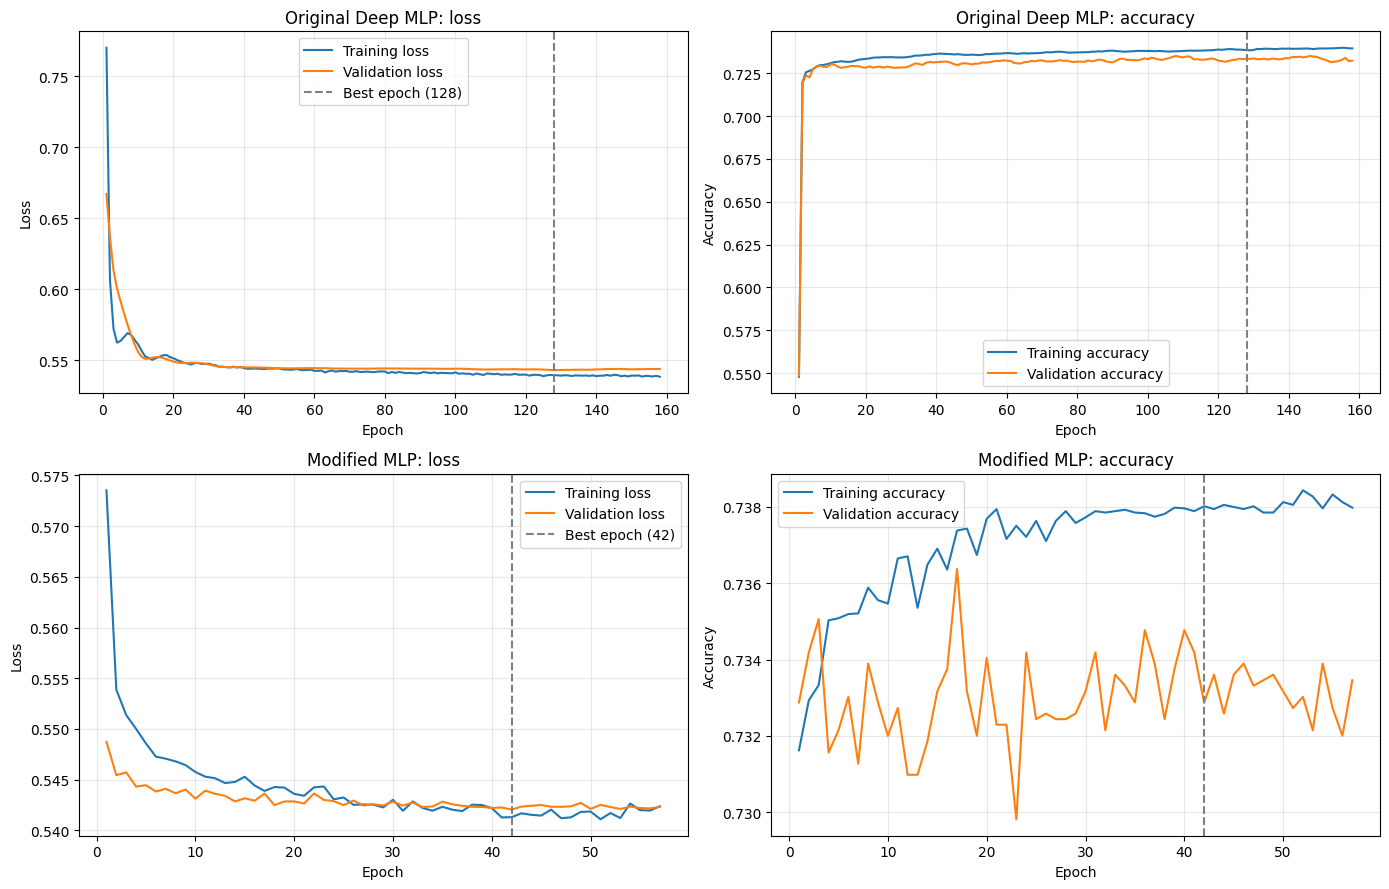

In [72]:
#================
# Training and validation curves (original vs. modified, first final seed)
#================
seed0 = FINAL_SEEDS[0]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, key in enumerate(["Original Deep MLP", "Modified MLP"]):
    h = final[key][seed0]["history"]
    ep = range(1, len(h["train_loss"]) + 1)
    best = final[key][seed0]["best_epoch"]

    axes[row, 0].plot(ep, h["train_loss"], label="Training loss")
    axes[row, 0].plot(ep, h["val_loss"], label="Validation loss")
    axes[row, 0].axvline(best, linestyle="--", color="gray", label=f"Best epoch ({best})")
    axes[row, 0].set_title(f"{key}: loss")
    axes[row, 0].set_xlabel("Epoch"); axes[row, 0].set_ylabel("Loss")

    axes[row, 1].plot(ep, h["train_accuracy"], label="Training accuracy")
    axes[row, 1].plot(ep, h["val_accuracy"], label="Validation accuracy")
    axes[row, 1].axvline(best, linestyle="--", color="gray")
    axes[row, 1].set_title(f"{key}: accuracy")
    axes[row, 1].set_xlabel("Epoch"); axes[row, 1].set_ylabel("Accuracy")

    for ax in axes[row]:
        ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Decision Threshold and Error Overlap (validation data only)

Classes are balanced, so the default threshold of 0.5 is the natural choice and is used for all headline results. As a secondary, clearly separated analysis, a threshold that maximises the validation F1-score is selected for each model (first final seed). It is applied once to the test set in the final cell.

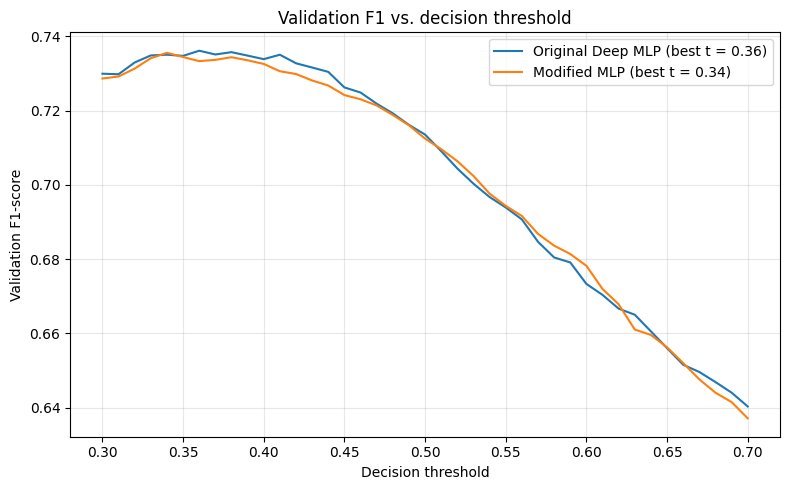

Thresholds selected on validation data: {'Original Deep MLP': 0.36000000000000004, 'Modified MLP': 0.34}


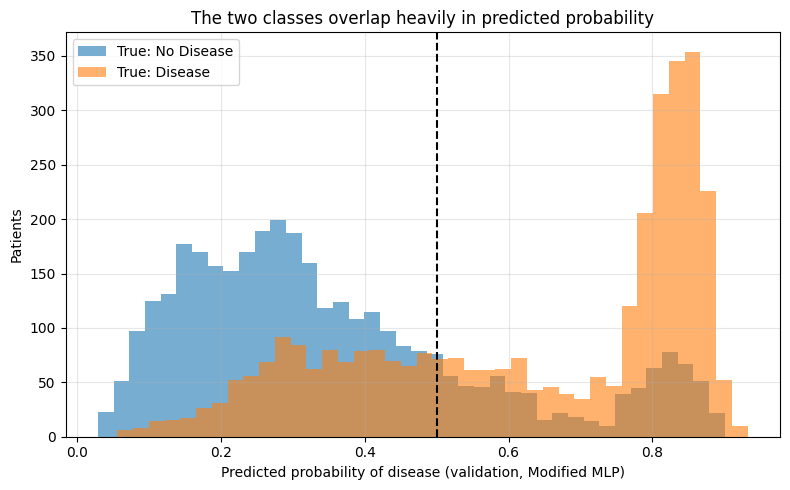

In [73]:
#================
# Validation-selected threshold (secondary analysis)
#================
thresholds = np.arange(0.30, 0.701, 0.01)
val_prob_final = {k: predict_proba_torch(final[k][seed0]["net"], REPS[final[k][seed0]["rep"]]["val"])
                  for k in ["Original Deep MLP", "Modified MLP"]}

BEST_THRESHOLD = {}
plt.figure(figsize=(8, 5))
for key, p in val_prob_final.items():
    f1s = [f1_score(y_val_np, p >= t) for t in thresholds]
    BEST_THRESHOLD[key] = float(thresholds[int(np.argmax(f1s))])
    plt.plot(thresholds, f1s, label=f"{key} (best t = {BEST_THRESHOLD[key]:.2f})")
plt.xlabel("Decision threshold"); plt.ylabel("Validation F1-score")
plt.title("Validation F1 vs. decision threshold")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("Thresholds selected on validation data:", BEST_THRESHOLD)

# Class-conditional probability distributions (validation): the overlap is the irreducible part
p_mod = val_prob_final["Modified MLP"]
plt.figure(figsize=(8, 5))
plt.hist(p_mod[y_val_np == 0], bins=40, alpha=0.6, label="True: No Disease")
plt.hist(p_mod[y_val_np == 1], bins=40, alpha=0.6, label="True: Disease")
plt.axvline(0.5, linestyle="--", color="black")
plt.xlabel("Predicted probability of disease (validation, Modified MLP)")
plt.ylabel("Patients")
plt.title("The two classes overlap heavily in predicted probability")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Freeze All Decisions

From this point on **no hyper-parameter, feature, architecture or threshold may change.** The next cell records the frozen configuration; the cell after it is the only place where the test set is used for the bonus experiment.

In [74]:
#================
# Freeze and save the configuration
#================
frozen = {
    "split": "StratifiedGroupKFold (80/10/10), random_state=42, grouped by identical feature rows",
    "selection_seeds": SELECTION_SEEDS,
    "final_seeds": FINAL_SEEDS,
    "original": ORIGINAL_CONFIG,
    "shallow": SHALLOW_CONFIG,
    "logistic_regression_C": LOGREG_C,
    "modified": {"name": SELECTED["name"], "representation": SELECTED["rep"],
                 "recipe": SELECTED["recipe"], "parameters": int(selected_row["params"])},
    "validation_thresholds": BEST_THRESHOLD,
}
with open("bonus_frozen_config.json", "w") as f:
    json.dump(frozen, f, indent=2)

torch.save({"state_dict": final["Modified MLP"][seed0]["net"].state_dict(),
            "config": frozen["modified"], "columns": REPS[SELECTED["rep"]]["columns"]},
           "best_modified_cardiovascular_mlp.pth")
print(json.dumps(frozen, indent=2))

{
  "split": "StratifiedGroupKFold (80/10/10), random_state=42, grouped by identical feature rows",
  "selection_seeds": [
    0,
    1,
    2
  ],
  "final_seeds": [
    42,
    123,
    2024
  ],
  "original": {
    "learning_rate": 0.01,
    "weight_decay": 0,
    "dropout": 0.3,
    "max_epochs": 400,
    "patience": 30
  },
  "shallow": {
    "learning_rate": 0.01,
    "weight_decay": 0,
    "max_epochs": 400,
    "patience": 30
  },
  "logistic_regression_C": 0.01,
  "modified": {
    "name": "C1 full + compact 64-32 (dropout 0.2)",
    "representation": "full",
    "recipe": {
      "lr": 0.001,
      "wd": 0.0001
    },
    "parameters": 3746
  },
  "validation_thresholds": {
    "Original Deep MLP": 0.36000000000000004,
    "Modified MLP": 0.34
  }
}


## Final Test Evaluation (single use of the test set)

In [75]:
#================
# Final Test Evaluation: every model is evaluated exactly once here
#================
y_test_np_final = y_test_tensor.cpu().numpy()
test_prob = {}                                   # model -> {seed: probabilities}
for key in final:
    test_prob[key] = {s: predict_proba_torch(final[key][s]["net"], REPS[final[key][s]["rep"]]["test"])
                      for s in FINAL_SEEDS}
test_prob_logreg = logreg_final.predict_proba(X_test_np)[:, 1]
test_prob_hgb = hgb_probe.predict_proba(X_test_np)[:, 1]

metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

# Per-seed metrics
per_seed_rows = []
for key in final:
    for s in FINAL_SEEDS:
        per_seed_rows.append({"Model": key, "Seed": s, **bonus_metrics(y_test_np_final, test_prob[key][s])})
per_seed_df = pd.DataFrame(per_seed_rows)
print("Per-seed test metrics")
display(per_seed_df.round(4))

# Mean +/- std over seeds
summary_rows = []
for key in ["Original Deep MLP", "Modified MLP", "Shallow MLP"]:
    sub = per_seed_df[per_seed_df["Model"] == key]
    row = {"Model": key, "Parameters": count_params(final[key][seed0]["net"])}
    for m in metric_names:
        row[m] = f"{sub[m].mean():.4f} ± {sub[m].std(ddof=0):.4f}"
    summary_rows.append(row)

for name, p, n_par in [("Logistic Regression", test_prob_logreg, X_train_np.shape[1] + 1),
                       ("Gradient boosting (diagnostic only)", test_prob_hgb, None)]:
    row = {"Model": name, "Parameters": n_par}
    for m, v in bonus_metrics(y_test_np_final, p).items():
        row[m] = f"{v:.4f} (single run)"
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
print("\nFINAL TEST RESULTS (mean ± std over 3 seeds; threshold 0.5)")
print("=" * 70)
display(summary_df)
summary_df.to_csv("bonus_results_summary.csv", index=False)

Per-seed test metrics


,Model,Seed,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original Deep MLP,42,0.7390,0.7566,0.6910,0.7223,0.8035
1,Original Deep MLP,123,0.7370,0.7499,0.6969,0.7225,0.8040
2,Original Deep MLP,2024,0.7377,0.7536,0.6925,0.7217,0.8038
3,Modified MLP,42,0.7387,0.7586,0.6866,0.7208,0.8039
4,Modified MLP,123,0.7380,0.7549,0.6910,0.7215,0.8036
5,Modified MLP,2024,0.7379,0.7531,0.6937,0.7222,0.8034
6,Shallow MLP,42,0.7367,0.7551,0.6866,0.7192,0.8032
7,Shallow MLP,123,0.7387,0.7528,0.6969,0.7238,0.8021
8,Shallow MLP,2024,0.7361,0.7493,0.6955,0.7214,0.8036



FINAL TEST RESULTS (mean ± std over 3 seeds; threshold 0.5)


,Model,Parameters,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Original Deep MLP,12386.0,0.7379 ± 0.0008,0.7534 ± 0.0027,0.6935 ± 0.0025,0.7222 ± 0.0003,0.8038 ± 0.0002
1,Modified MLP,3746.0,0.7382 ± 0.0004,0.7555 ± 0.0023,0.6904 ± 0.0029,0.7215 ± 0.0006,0.8037 ± 0.0002
2,Shallow MLP,450.0,0.7372 ± 0.0011,0.7524 ± 0.0024,0.6930 ± 0.0046,0.7215 ± 0.0019,0.8030 ± 0.0006
3,Logistic Regression,12.0,0.7294 (single run),0.7516 (single run),0.6708 (single run),0.7089 (single run),0.7915 (single run)
4,Gradient boosting (diagnostic only),NaN,0.7374 (single run),0.7497 (single run),0.6987 (single run),0.7233 (single run),0.8030 (single run)



Original Deep MLP (seed 42): per-class report on the test set
                precision    recall  f1-score   support

No Disease (0)     0.7247    0.7854    0.7539      3490
   Disease (1)     0.7566    0.6910    0.7223      3369

      accuracy                         0.7390      6859
     macro avg     0.7407    0.7382    0.7381      6859
  weighted avg     0.7404    0.7390    0.7384      6859


Modified MLP (seed 42): per-class report on the test set
                precision    recall  f1-score   support

No Disease (0)     0.7228    0.7891    0.7545      3490
   Disease (1)     0.7586    0.6866    0.7208      3369

      accuracy                         0.7387      6859
     macro avg     0.7407    0.7378    0.7377      6859
  weighted avg     0.7404    0.7387    0.7380      6859



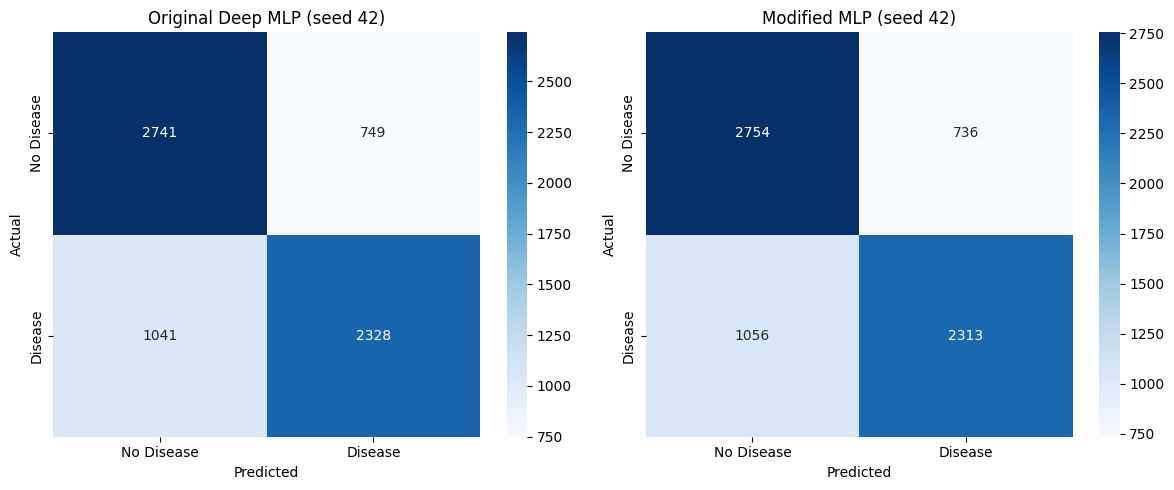

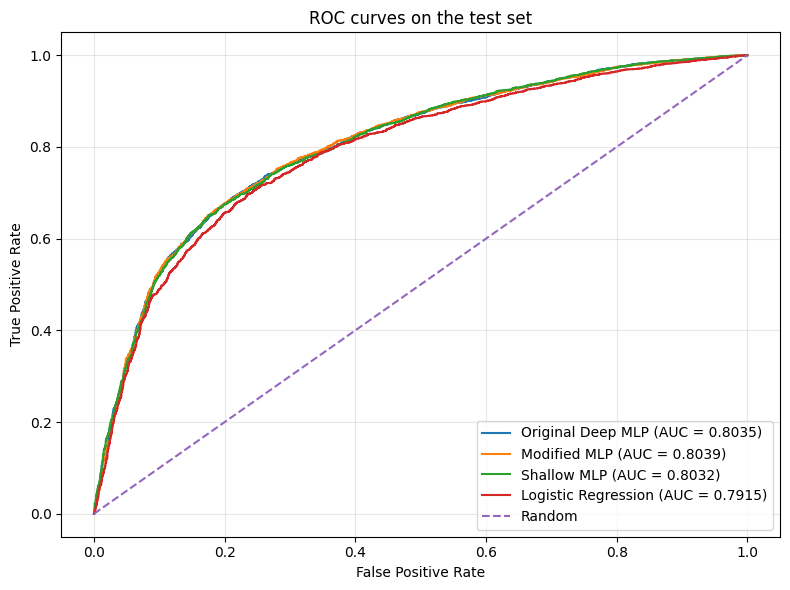

In [76]:
#================
# Per-class report, confusion matrices and ROC (first final seed)
#================
for key in ["Original Deep MLP", "Modified MLP"]:
    print(f"\n{key} (seed {seed0}): per-class report on the test set")
    print(classification_report(y_test_np_final, (test_prob[key][seed0] >= 0.5).astype(int),
                                target_names=["No Disease (0)", "Disease (1)"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, key in zip(axes, ["Original Deep MLP", "Modified MLP"]):
    cm_ = confusion_matrix(y_test_np_final, (test_prob[key][seed0] >= 0.5).astype(int))
    sns.heatmap(cm_, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
    ax.set_title(f"{key} (seed {seed0})"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
for key in ["Original Deep MLP", "Modified MLP", "Shallow MLP"]:
    fpr, tpr, _ = roc_curve(y_test_np_final, test_prob[key][seed0])
    plt.plot(fpr, tpr, label=f"{key} (AUC = {roc_auc_score(y_test_np_final, test_prob[key][seed0]):.4f})")
fpr, tpr, _ = roc_curve(y_test_np_final, test_prob_logreg)
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test_np_final, test_prob_logreg):.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves on the test set"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [77]:
#================
# Is the difference real? Paired bootstrap on the test set (3-seed averages)
#================
rng = np.random.RandomState(123)
n_test = len(y_test_np_final)
N_BOOT = 1000
diffs = {"Accuracy": [], "ROC-AUC": []}

for _ in range(N_BOOT):
    idx = rng.randint(0, n_test, n_test)
    yt = y_test_np_final[idx]
    res = {}
    for key in ["Original Deep MLP", "Modified MLP"]:
        res[key] = {
            "Accuracy": np.mean([accuracy_score(yt, test_prob[key][s][idx] >= 0.5) for s in FINAL_SEEDS]),
            "ROC-AUC": np.mean([roc_auc_score(yt, test_prob[key][s][idx]) for s in FINAL_SEEDS]),
        }
    for m in diffs:
        diffs[m].append(res["Modified MLP"][m] - res["Original Deep MLP"][m])

boot_rows = []
for m, d in diffs.items():
    lo, hi = np.percentile(d, [2.5, 97.5])
    boot_rows.append({"Metric": m, "Mean difference (Modified − Original)": np.mean(d),
                      "95% CI low": lo, "95% CI high": hi,
                      "Distinguishable from 0?": "yes" if (lo > 0 or hi < 0) else "no"})
boot_df = pd.DataFrame(boot_rows)
display(boot_df.round(4))

,Metric,Mean difference (Modified − Original),95% CI low,95% CI high,Distinguishable from 0?
0,Accuracy,0.0003,-0.0020,0.0025,no
1,ROC-AUC,-0.0001,-0.0012,0.0009,no


In [78]:
#================
# Secondary: test results at the validation-selected threshold
#================
thr_rows = []
for key in ["Original Deep MLP", "Modified MLP"]:
    t = BEST_THRESHOLD[key]
    vals = [bonus_metrics(y_test_np_final, test_prob[key][s], threshold=t) for s in FINAL_SEEDS]
    row = {"Model": key, "Threshold": t}
    for m in metric_names[:4]:
        row[m] = f"{np.mean([v[m] for v in vals]):.4f} ± {np.std([v[m] for v in vals]):.4f}"
    thr_rows.append(row)
display(pd.DataFrame(thr_rows))
print("(The threshold was chosen for the first seed on validation data and reused for all seeds.)")

,Model,Threshold,Accuracy,Precision,Recall,F1-score
0,Original Deep MLP,0.36,0.7122 ± 0.0020,0.6693 ± 0.0046,0.8189 ± 0.0084,0.7365 ± 0.0007
1,Modified MLP,0.34,0.7063 ± 0.0014,0.6580 ± 0.0018,0.8369 ± 0.0016,0.7368 ± 0.0005


(The threshold was chosen for the first seed on validation data and reused for all seeds.)


## Discussion

**What limits performance.** The investigation shows that the plateau around 0.80 ROC-AUC / 0.74 accuracy is a property of the dataset, not of the network. A much more flexible learner, a linear model, a 450-parameter MLP and the 12k-parameter Deep MLP all land within about 0.01 AUC of each other; learning curves are flat long before the full training set is used; and a handful of variables (systolic BP, age, cholesterol) hold almost all of the signal. The remaining error comes from overlapping classes: patients with the same coarse measurements can have different outcomes. Class imbalance is not an issue (≈ 50/50), so re-weighting would only shift the precision/recall trade-off, which the decision threshold already controls.

**What the modification changes.** The modified model changes three things relative to the original: (1) clinically motivated engineered inputs (BMI, pulse pressure, mean arterial pressure, log blood pressure, one-hot cholesterol/glucose, ACC/AHA blood-pressure stage) fitted on the training split only; (2) a mini-batch AdamW recipe with learning-rate scheduling instead of 400 full-batch steps; (3) the architecture selected on the validation set by the declared rule (see the *Candidate Selection* table and the printed selection). The ablation ladder (A1 → A3 → C1–C5) shows how much each of these contributes on validation data.

**How to read the result.** Use the *Final Test Evaluation* tables together with the paired bootstrap. If the 95% confidence interval of the difference includes zero, the honest conclusion is that the modification does **not** produce a measurable gain over the original on this dataset; any benefit is then limited to efficiency (fewer parameters, faster and more stable convergence) rather than accuracy. If the interval excludes zero, report the gain with its size, which is expected to be small (on the order of a tenth of a percentage point). Either outcome is valid under the guidelines, which require a fair comparison rather than a particular number.

**Limitations.** (i) The test set contains about 6,900 patients, so differences below roughly half a percentage point are inside sampling noise. (ii) Seeds change initialisation and batch order but not the split. (iii) Results are for this dataset only; we do not claim to beat the original paper, which would require running both models on the paper's dataset as well. (iv) Gradient boosting appears only as a diagnostic probe and is not part of the proposed solution.

**What each member did** is documented in the project report.